In [1]:
import os
import shutil
import subprocess
import tempfile
from pathlib import Path

VOLUME = Path("/workspace")
ROOT = VOLUME / "B3IT_Figure1_Phi4Mini"
REPO = ROOT / "repo"
URL = "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis"
COMMIT = "ad2f69295797a5f03e7b480246080d91087d9007"

def run(*args):
    result = subprocess.run(args, text=True, capture_output=True)
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or result.stdout.strip() or str(args))
    return result.stdout.strip()

print("RunPod pod ID:", os.environ.get("RUNPOD_POD_ID", "(unavailable)"))
print("GPU name, total VRAM, free VRAM (MiB):")
print(run("nvidia-smi", "--query-gpu=name,memory.total,memory.free",
          "--format=csv,noheader,nounits"))

print("\nWorkspace mount:")
print(run("findmnt", "-T", str(VOLUME), "-o", "TARGET,SOURCE,FSTYPE,OPTIONS"))
print("\nDisk capacity:")
print(run("df", "-h", "/", str(VOLUME)))

mount_target = run("findmnt", "-n", "-T", str(VOLUME), "-o", "TARGET")
if mount_target != str(VOLUME) or VOLUME.is_symlink():
    raise RuntimeError("Expected a dedicated mount at /workspace. Share the output before continuing.")
if not os.access(VOLUME, os.W_OK | os.X_OK):
    raise RuntimeError("/workspace is not writable by this notebook.")

# Refuse redirected paths before creating anything.
for path in (ROOT, REPO, *(ROOT / name for name in
                          ("configs", "logs", "data", "checkpoints", "results"))):
    if path.is_symlink():
        raise RuntimeError(f"Unexpected symlink at {path}. Stopping.")

ROOT.mkdir(exist_ok=True)
if REPO.exists():
    # On a retry, verify the existing clone without modifying it.
    if run("git", "-C", str(REPO), "rev-parse", "--show-toplevel") != str(REPO):
        raise RuntimeError(f"{REPO} is not the root of its own Git checkout.")
else:
    # Publish the clone only after checkout succeeds, so a retry is safe.
    with tempfile.TemporaryDirectory(prefix=".clone-", dir=ROOT) as tmp:
        staged = Path(tmp) / "repo"
        run("git", "clone", "--no-checkout", URL, str(staged))
        run("git", "-C", str(staged), "checkout", "--detach", COMMIT)
        staged.rename(REPO)

origin = run("git", "-C", str(REPO), "remote", "get-url", "origin")
head = run("git", "-C", str(REPO), "rev-parse", "HEAD")
if origin != URL or head != COMMIT:
    raise RuntimeError(f"Checkout mismatch. Origin: {origin}\nHEAD: {head}")

project = REPO / "track-llm-apis"
if not (project / "pyproject.toml").is_file():
    raise RuntimeError(f"Missing pyproject.toml in {project}")

for name in ("configs", "logs", "data", "checkpoints", "results"):
    (ROOT / name).mkdir(exist_ok=True)

print("\nVerified commit:", head)
print("Python project:", project)
print("Experiment folder:", ROOT)
print("Free space on /workspace (GiB):", round(shutil.disk_usage(ROOT).free / 2**30, 1))

RunPod pod ID: 8a1pqi5ocashul
GPU name, total VRAM, free VRAM (MiB):
NVIDIA RTX A5000, 24564, 24114

Workspace mount:
TARGET     SOURCE                                                  FSTYPE OPTIONS
/workspace mfs#eu-se-1.runpod.net:9421[/networkvolumes/flrv32qt7x] fuse   rw,nosuid,nodev,relatime,user_id=0,group_id=0,allow_other

Disk capacity:
Filesystem                   Size  Used Avail Use% Mounted on
overlay                       50G   16M   50G   1% /
mfs#eu-se-1.runpod.net:9421  700T  420T  280T  60% /workspace

Verified commit: ad2f69295797a5f03e7b480246080d91087d9007
Python project: /workspace/B3IT_Figure1_Phi4Mini/repo/track-llm-apis
Experiment folder: /workspace/B3IT_Figure1_Phi4Mini
Free space on /workspace (GiB): 286648.4


Step 2 — Install the locked environment on the container disk

In [2]:
import os
import subprocess
import sys
from pathlib import Path

project = Path("/workspace/B3IT_Figure1_Phi4Mini/repo/track-llm-apis")
log_path = Path("/workspace/B3IT_Figure1_Phi4Mini/logs/install.log")
local = Path("/tmp/b3it-phi4mini")
venv = local / "venv"

if not (project / "uv.lock").is_file():
    raise RuntimeError(f"Missing {project / 'uv.lock'}. Stop here and share the output.")

for key, value in {
    "UV_PROJECT_ENVIRONMENT": str(venv),
    "UV_CACHE_DIR": str(local / "uv-cache"),
    "UV_PYTHON_INSTALL_DIR": str(local / "python"),
    "HF_HOME": str(local / "huggingface"),
    "HF_HUB_CACHE": str(local / "huggingface" / "hub"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}.items():
    os.environ[key] = value

local.mkdir(parents=True, exist_ok=True)
if local.stat().st_dev == project.stat().st_dev:
    raise RuntimeError("/tmp and the Phi project share a filesystem. Stop before installing.")

def install_step(args, log):
    result = subprocess.run(
        [str(arg) for arg in args], cwd=project,
        stdout=log, stderr=subprocess.STDOUT,
    )
    log.flush()
    if result.returncode:
        tail = log_path.read_text(errors="replace").splitlines()[-40:]
        raise RuntimeError("\n".join(tail) or f"Command failed: {args}")

import shutil
uv = shutil.which("uv")
with log_path.open("w", buffering=1) as log:
    if uv is None:
        print("Installing uv on the container disk…", flush=True)
        bootstrap = local / "uv-bootstrap"
        install_step([sys.executable, "-m", "venv", bootstrap], log)
        install_step([bootstrap / "bin/python", "-m", "pip", "install",
                      "--no-cache-dir", "uv"], log)
        uv = str(bootstrap / "bin/uv")

    print("Preparing Python 3.11…", flush=True)
    install_step([uv, "python", "install", "3.11"], log)

    print("Installing dependencies from uv.lock. This may take several minutes…",
          flush=True)
    install_step([uv, "sync", "--locked", "--python", "3.11"], log)

phi_python = venv / "bin/python"
check = subprocess.run(
    [str(phi_python), "-c", """
import sys
import torch
from importlib.metadata import version

print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("vLLM:", version("vllm"))
print("Transformers:", version("transformers"))
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
"""],
    cwd=project, text=True, capture_output=True,
)
print(check.stdout, end="")
if check.returncode:
    raise RuntimeError(check.stderr.strip())
print("Install log:", log_path)

Preparing Python 3.11…
Installing dependencies from uv.lock. This may take several minutes…
Interpreter: /tmp/b3it-phi4mini/venv/bin/python
Python: 3.11.17
PyTorch: 2.9.1+cu128
PyTorch CUDA build: 12.8
vLLM: 0.15.0
Transformers: 4.57.6
CUDA available: True
GPU: NVIDIA RTX A5000
Install log: /workspace/B3IT_Figure1_Phi4Mini/logs/install.log


Step 3 — Test Phi with one generated token in FP16

In [3]:
import json
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
local = Path("/tmp/b3it-phi4mini")
python = local / "venv/bin/python"
script = root / "configs/phi_fp16_smoke.py"
log = root / "logs/phi_fp16_smoke.log"
report = root / "results/phi_fp16_smoke.json"

script.write_text(textwrap.dedent("""\
    import json
    from importlib.metadata import version
    from pathlib import Path

    import torch
    from transformers import AutoConfig
    from vllm import LLM, SamplingParams

    MODEL = "microsoft/Phi-4-mini-instruct"
    ROOT = Path(__file__).resolve().parents[1]

    def main():
        cfg = AutoConfig.from_pretrained(MODEL)
        revision = getattr(cfg, "_commit_hash", None)
        if not revision:
            raise RuntimeError("Could not resolve the Hugging Face checkpoint revision.")
        declared_dtype = str(getattr(cfg, "dtype", None))
        print("Checkpoint revision:", revision, flush=True)
        print("Checkpoint config dtype:", declared_dtype, flush=True)

        llm = LLM(
            model=MODEL,
            revision=revision,
            tokenizer_revision=revision,
            dtype="float16",
            seed=0,
            max_model_len=1024,
            max_num_seqs=64,
            enforce_eager=True,
            enable_prefix_caching=False,
        )
        actual_dtype = llm.llm_engine.model_config.dtype
        if actual_dtype != torch.float16:
            raise RuntimeError(f"Expected FP16, got {actual_dtype}")

        tokenizer = llm.get_tokenizer()
        prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": "What is the capital of France?"}],
            tokenize=True,
            add_generation_prompt=True,
        )
        output = llm.generate(
            [{"prompt_token_ids": prompt}],
            SamplingParams(temperature=0, max_tokens=1, seed=0),
            use_tqdm=False,
        )[0].outputs[0]
        if len(output.token_ids) != 1:
            raise RuntimeError(f"Expected exactly one token, got {output.token_ids}")

        result = {
            "model": MODEL,
            "revision": revision,
            "checkpoint_config_dtype": declared_dtype,
            "evaluation_dtype": str(actual_dtype),
            "gpu": torch.cuda.get_device_name(0),
            "inference_backend": "vLLM",
            "vllm": version("vllm"),
            "torch": str(torch.__version__),
            "transformers": version("transformers"),
            "prompt_tokens": len(prompt),
            "generated_token_ids": list(output.token_ids),
            "generated_text": output.text,
        }
        path = ROOT / "results/phi_fp16_smoke.json"
        path.write_text(json.dumps(result, indent=2) + "\\n")

    if __name__ == "__main__":
        main()
"""))

env = os.environ.copy()
env.update({
    "HF_HOME": str(local / "huggingface"),
    "HF_HUB_CACHE": str(local / "huggingface/hub"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "PYTHONUNBUFFERED": "1",
})

print("Downloading/loading Phi and testing FP16. Progress log:", log, flush=True)
with log.open("w") as stream:
    proc = subprocess.run(
        [str(python), str(script)],
        env=env, stdout=stream, stderr=subprocess.STDOUT,
    )

lines = log.read_text(errors="replace").splitlines()
if proc.returncode:
    print("\n".join(lines[-60:]))
    raise RuntimeError(f"Phi smoke test failed (exit {proc.returncode}).")

print(report.read_text())
for line in lines:
    if "backend" in line.lower() and "attention" in line.lower():
        print(line)

Downloading/loading Phi and testing FP16. Progress log: /workspace/B3IT_Figure1_Phi4Mini/logs/phi_fp16_smoke.log
{
  "model": "microsoft/Phi-4-mini-instruct",
  "revision": "cfbefacb99257ffa30c83adab238a50856ac3083",
  "checkpoint_config_dtype": "torch.bfloat16",
  "evaluation_dtype": "torch.float16",
  "gpu": "NVIDIA RTX A5000",
  "inference_backend": "vLLM",
  "vllm": "0.15.0",
  "torch": "2.9.1+cu128",
  "transformers": "4.57.6",
  "prompt_tokens": 10,
  "generated_token_ids": [
    976
  ],
  "generated_text": "The"
}

(EngineCore_DP0 pid=897) INFO 11-11 22:10:49 [cuda.py:364] Using FLASH_ATTN attention backend out of potential backends: ('FLASH_ATTN', 'FLASHINFER', 'TRITON_ATTN', 'FLEX_ATTENTION')


Step 4 — Copy and verify the traffic pool

In [4]:
import hashlib
import json
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
dest = root / "data/traffic_pool.json"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
revision = json.loads((root / "results/phi_fp16_smoke.json").read_text())["revision"]

# Skip large dependency, cache, and model directories during the file search.
skip = {".git", ".venv", "venv", ".cache", "__pycache__", "node_modules",
        "site-packages", "huggingface", "checkpoints"}
candidates = []
for directory, dirs, files in os.walk("/workspace"):
    dirs[:] = [d for d in dirs if d not in skip]
    if "traffic_pool.json" in files:
        candidates.append(Path(directory) / "traffic_pool.json")

if not candidates:
    raise FileNotFoundError(
        f"No traffic_pool.json found. Upload your verified file to {dest}, "
        "then rerun this cell."
    )

def get_prompts(data):
    if isinstance(data, dict):
        for key in ("traffic_pool", "prompts", "traffic", "background_prompts"):
            if key in data:
                data = data[key]
                break
    if not isinstance(data, list):
        return None
    if all(isinstance(item, str) for item in data):
        return data
    if all(isinstance(item, dict) and isinstance(item.get("prompt"), str)
           for item in data):
        return [item["prompt"] for item in data]
    return None

matches = []
for path in sorted(candidates):
    raw = path.read_bytes()
    data = json.loads(raw)
    prompts = get_prompts(data)
    digest = hashlib.sha256(raw).hexdigest()
    count = len(prompts) if prompts is not None else "unrecognized format"
    print(f"{path}\n  prompts={count}  sha256={digest}", flush=True)
    if count == 3138:
        matches.append((path, digest, prompts))

if not matches:
    raise ValueError("No recognized 3,138-prompt pool. Paste the output here.")
if len({digest for _, digest, _ in matches}) != 1:
    raise ValueError("Different 3,138-prompt pools found. Paste the paths and hashes.")

source, digest, prompts = matches[0]
if dest.exists() and hashlib.sha256(dest.read_bytes()).hexdigest() != digest:
    raise ValueError(f"The existing Phi copy differs from the source. Stopped at {dest}.")
if not dest.exists():
    temp = dest.with_suffix(".json.tmp")
    temp.write_bytes(source.read_bytes())
    if hashlib.sha256(temp.read_bytes()).hexdigest() != digest:
        raise ValueError("The source changed during copying. Rerun this cell.")
    temp.replace(dest)

assert hashlib.sha256(dest.read_bytes()).hexdigest() == digest
print(f"\nVerified Phi copy: {dest}", flush=True)

# Use the Phi environment and cached tokenizer, independent of the notebook kernel.
check = r"""
import json, sys
from transformers import AutoTokenizer

revision = sys.argv[1]
prompts = json.load(sys.stdin)
tok = AutoTokenizer.from_pretrained(
    "microsoft/Phi-4-mini-instruct", revision=revision, local_files_only=True
)
for special in (False, True):
    lengths = sorted(len(ids) for ids in tok(
        prompts, add_special_tokens=special, truncation=False,
        return_attention_mask=False, verbose=False
    )["input_ids"])
    print(f"add_special_tokens={special}: min={lengths[0]}, "
          f"median={lengths[len(lengths)//2]}, max={lengths[-1]}, "
          f"over_1023={sum(n > 1023 for n in lengths)}")
"""
env = os.environ.copy()
env["HF_HUB_CACHE"] = "/tmp/b3it-phi4mini/huggingface/hub"
result = subprocess.run(
    [str(python), "-c", check, revision],
    input=json.dumps(prompts), text=True, capture_output=True, env=env,
)
if result.returncode:
    raise RuntimeError(result.stderr)
print(result.stdout)

/workspace/B3IT_Figure1_Gemma1B/data/traffic_pool.json
  prompts=3138  sha256=36346d55187fbe80d5756f9cef51e0316a3e8ca89a9bc9140bc2a6a5e9a41ea4

Verified Phi copy: /workspace/B3IT_Figure1_Phi4Mini/data/traffic_pool.json
add_special_tokens=False: min=1, median=13, max=898, over_1023=0
add_special_tokens=True: min=1, median=13, max=898, over_1023=0



In [6]:
import subprocess
from pathlib import Path

repo = Path("/workspace/B3IT_Figure1_Phi4Mini/repo")
commit = "ad2f69295797a5f03e7b480246080d91087d9007"

def git(*args):
    return subprocess.check_output(["git", "-C", str(repo), *args], text=True)

paths = git("ls-tree", "-r", "--name-only", commit, "track-llm-apis").splitlines()

for name in ("bi_phase_1.py", "vllm_sampling.py"):
    matches = [p for p in paths if p.endswith(f"/sampling/{name}")]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one sampling/{name}. Found: {matches}")
    path = matches[0]
    print(f"\n### {path}\n")
    print(git("show", f"{commit}:{path}"))


### track-llm-apis/src/track_llm_apis/sampling/bi_phase_1.py

"""BI Phase 1: Identify and validate border inputs.

Phase 1a: Identify border inputs by querying models with single-token inputs.
Phase 1b: Validate border inputs by querying each one multiple times.
"""

import random
import time
from datetime import timedelta
from pathlib import Path
from typing import Any

import fire
import orjson
from pydantic import BaseModel, Field
from transformers import AutoTokenizer, PreTrainedTokenizerBase

from track_llm_apis.config import config
from track_llm_apis.sampling.vllm_sampling import cleanup_vllm, init_vllm_bi, vllm_inference_bi
from track_llm_apis.util import slugify

logger = config.logger


class BIPhase1ModelResult(BaseModel):
    """Results for a single model in BI phase 1."""

    model_name: str
    bi_config: dict[str, Any]
    phase: str
    # Map from input token string to Counter of output token strings
    # Using dict[str, int] as Pydantic-serializable Counter represen

Step 6 — Edit the original Phi checkout and run Phase 1a

In [7]:
import ast
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis/sampling"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
bi_file = pkg / "bi_phase_1.py"
vllm_file = pkg / "vllm_sampling.py"

# Edit only the dedicated BI initializer, leaving other vLLM loaders alone.
vtext = vllm_file.read_text()
old_sig = "def init_vllm_bi(model_name: str, device: str) -> LLM:"
new_sig = "def init_vllm_bi(model_name: str, device: str, **engine_options) -> LLM:"

if old_sig in vtext:
    before, body = vtext.split(old_sig, 1)
    anchor = "        gpu_memory_utilization=vllm_memory,\n"
    if body.count(anchor) != 1:
        raise RuntimeError("Unexpected init_vllm_bi source. Paste this error.")
    body = body.replace(anchor, anchor + "        **engine_options,\n", 1)
    vtext = before + new_sig + body
elif new_sig not in vtext or "**engine_options," not in vtext.split(new_sig, 1)[1]:
    raise RuntimeError("Unexpected local edit in init_vllm_bi. Paste this error.")

addition = textwrap.dedent('''
def phase_1a_phi() -> None:
    """Discover Phi border inputs using persistent 1,000-candidate checkpoints."""
    import hashlib
    import json

    root = Path(__file__).resolve().parents[5]
    model = "microsoft/Phi-4-mini-instruct"
    revision = "cfbefacb99257ffa30c83adab238a50856ac3083"
    expected_hash = "36346d55187fbe80d5756f9cef51e0316a3e8ca89a9bc9140bc2a6a5e9a41ea4"
    pool_bytes = (root / "data/traffic_pool.json").read_bytes()
    if hashlib.sha256(pool_bytes).hexdigest() != expected_hash:
        raise ValueError("Traffic pool checksum mismatch.")
    traffic = json.loads(pool_bytes)
    if isinstance(traffic, dict):
        traffic = next(traffic[k] for k in
                       ("traffic_pool", "prompts", "traffic", "background_prompts")
                       if k in traffic)
    if traffic and isinstance(traffic[0], dict):
        traffic = [row["prompt"] for row in traffic]
    if len(traffic) != 3138 or not all(isinstance(p, str) for p in traffic):
        raise ValueError("Unexpected traffic pool format.")

    def save(path, value):
        temp = path.with_suffix(".tmp")
        temp.write_bytes(orjson.dumps(value))
        temp.replace(path)

    tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)
    candidates = get_single_token_inputs(tokenizer, 20000, seed=0)
    if len(candidates) != 20000 or len(set(candidates)) != 20000:
        raise ValueError(f"Expected 20,000 unique candidates. Found {len(set(candidates))}.")

    settings = dict(
        model=model, revision=revision, dtype="float16", seed=0,
        temperature=0.0, max_tokens=1, batch_size=64,
        per_batch_input_fraction=0.95, max_model_len=1024, max_num_seqs=64,
        enforce_eager=True, enable_prefix_caching=False,
        candidates=20000, queries=3, chunk_size=1000,
        grouping="three passes within each consecutive 1000-candidate group",
        traffic_sha256=expected_hash,
        candidates_sha256=hashlib.sha256(orjson.dumps(candidates)).hexdigest(),
    )
    checkpoint = root / "checkpoints/phase_1a_progress.json"
    final = root / "results/phase_1a_phi.json"
    next_index, counts, lengths, elapsed = 0, {}, {}, 0.0
    rng_state = None

    if checkpoint.exists():
        state = orjson.loads(checkpoint.read_bytes())
        if state["settings"] != settings:
            raise ValueError("Saved checkpoint belongs to a different configuration.")
        next_index = state["next_index"]
        counts, lengths = state["counts"], state["prompt_lengths"]
        elapsed = state["generation_time"]
        if next_index not in range(0, 20001, 1000):
            raise ValueError("Invalid checkpoint position.")
        expected = set(candidates[:next_index])
        if set(counts) != expected or set(lengths) != expected:
            raise ValueError("Checkpoint is missing candidates or prompt lengths.")
        if any(sum(tokens.values()) != 3 for tokens in counts.values()):
            raise ValueError("Checkpoint contains incomplete observations.")
        version, internal, gauss = state["rng_state"]
        rng_state = (version, tuple(internal), gauss)
        print(f"Resuming at {next_index:,}/20,000 candidates.", flush=True)

    if next_index < len(candidates):
        llm = init_vllm_bi(
            model, "cuda:0", revision=revision, tokenizer_revision=revision,
            dtype="float16", seed=0, max_model_len=1024,
            max_num_seqs=64, enable_prefix_caching=False,
        )
        # Initialize batching RNG after engine startup, including when resuming.
        if rng_state is None:
            random.seed(0)
        else:
            random.setstate(rng_state)
        try:
            for start in range(next_index, len(candidates), 1000):
                chunk = candidates[start:start + 1000]
                tick = time.monotonic()
                batch = vllm_inference_bi(
                    llm=llm, inputs=chunk, traffic_prompts=traffic,
                    n_samples=3, temperature=0.0, input_fraction=0.95,
                    batch_size=64, max_tokens=1,
                )
                elapsed += time.monotonic() - tick
                counts.update(batch.counts)
                lengths.update(batch.prompt_lengths)
                end = start + len(chunk)
                save(checkpoint, dict(
                    settings=settings, next_index=end, counts=counts,
                    prompt_lengths=lengths, generation_time=elapsed,
                    rng_state=random.getstate(),
                ))
                found = sum(len(tokens) >= 2 for tokens in counts.values())
                print(f"Saved {end:,}/20,000 candidates | {found} border inputs",
                      flush=True)
        finally:
            cleanup_vllm(llm)

    result = BIPhase1ModelResult(
        model_name=model, bi_config=settings, phase="1a", results=counts,
        prompt_lengths=lengths, generation_time=elapsed,
    )
    save(root / "data/phase_1a_phi_candidate_order.json", candidates)
    save(final, result.model_dump(mode="json"))
    print(f"Phase 1a complete: {len(result.get_border_inputs())} border inputs "
          f"from 60,000 observations. Saved {final}", flush=True)
''').strip()

btext = bi_file.read_text()
anchor = 'if __name__ == "__main__":'
if "def phase_1a_phi(" not in btext:
    if btext.count(anchor) != 1:
        raise RuntimeError("Unexpected bi_phase_1.py entry point.")
    btext = btext.replace(anchor, addition + "\n\n\n" + anchor)
elif addition not in btext:
    raise RuntimeError("An existing phase_1a_phi implementation differs. Paste this error.")

# Validate both edits before writing. The same cell can be rerun after interruption.
for path, source in ((vllm_file, vtext), (bi_file, btext)):
    ast.parse(source, filename=str(path))
for path, source in ((vllm_file, vtext), (bi_file, btext)):
    if path.read_text() != source:
        temp = path.with_suffix(".py.tmp")
        temp.write_text(source)
        temp.replace(path)

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "PYTHONPATH": str(project / "src"),
    "PYTHONUNBUFFERED": "1",
})

# A process lock prevents two notebook launches from writing the same checkpoint.
import fcntl
lock_path = root / "checkpoints/phase_1a.lock"
log_path = root / "logs/phase_1a.log"
entry = "from track_llm_apis.sampling.bi_phase_1 import phase_1a_phi; phase_1a_phi()"

with lock_path.open("a") as lock, log_path.open("a", buffering=1) as log:
    try:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        raise RuntimeError("Phi discovery is already running. Check logs/phase_1a.log.")
    print("Starting Phi discovery. First checkpoint at 1,000 candidates.", flush=True)
    with subprocess.Popen(
        [str(python), "-c", entry], cwd=project, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        pass_fds=(lock.fileno(),),
    ) as proc:
        try:
            for line in proc.stdout:
                log.write(line)
                print(line, end="", flush=True)
        except KeyboardInterrupt:
            proc.terminate()
            raise
        if proc.wait() != 0:
            raise RuntimeError(f"Phase 1a stopped. See {log_path}.")


Starting Phi discovery. First checkpoint at 1,000 candidates.
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=1914) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=1914) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:07<00:07,  7.87s/it]
(EngineCore_DP0 pid=1914) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00, 10.24s/it]
(EngineCore_DP0 pid=1914) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00,  9.88s/it]
(EngineCore_DP0 pid=1914) 
(EngineCore_DP0 pid=1914) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=1914) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
Saved

Step 7 — Calibrate all 319 Phi border inputs

In [8]:
import ast
import fcntl
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
source_file = project / "src/track_llm_apis/sampling/bi_phase_1.py"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")

addition = textwrap.dedent('''
def phase_1b_phi() -> None:
    """Calibrate Phi's discovered inputs and checkpoint each group of ten."""
    import hashlib

    root = Path(__file__).resolve().parents[5]
    phase_a_bytes = (root / "results/phase_1a_phi.json").read_bytes()
    phase_a = BIPhase1ModelResult.model_validate(orjson.loads(phase_a_bytes))
    settings_a = phase_a.bi_config
    inputs = phase_a.get_border_inputs()

    if phase_a.phase != "1a" or phase_a.model_name != "microsoft/Phi-4-mini-instruct":
        raise ValueError("Unexpected discovery result.")
    if len(phase_a.results) != 20000 or len(inputs) != 319:
        raise ValueError(f"Unexpected discovery counts: {len(phase_a.results)}, {len(inputs)}.")
    if any(sum(c.values()) != 3 for c in phase_a.results.values()):
        raise ValueError("A discovery candidate has an incomplete count.")

    raw = (root / "data/traffic_pool.json").read_bytes()
    if hashlib.sha256(raw).hexdigest() != settings_a["traffic_sha256"]:
        raise ValueError("Traffic file differs from discovery.")
    traffic = orjson.loads(raw)
    if isinstance(traffic, dict):
        traffic = next(traffic[k] for k in
                       ("traffic_pool", "prompts", "traffic", "background_prompts")
                       if k in traffic)
    if traffic and isinstance(traffic[0], dict):
        traffic = [row["prompt"] for row in traffic]
    if len(traffic) != 3138 or not all(isinstance(p, str) for p in traffic):
        raise ValueError("Unexpected traffic pool format.")

    settings = {
        key: settings_a[key] for key in (
            "model", "revision", "dtype", "seed", "temperature", "max_tokens",
            "batch_size", "per_batch_input_fraction", "max_model_len",
            "max_num_seqs", "enforce_eager", "enable_prefix_caching", "traffic_sha256"
        )
    }
    settings.update(
        queries=1000, chunk_size=10, input_count=len(inputs),
        order="phase_1a.get_border_inputs()",
        grouping="1000 passes within each consecutive group of up to 10 inputs",
        discovery_sha256=hashlib.sha256(phase_a_bytes).hexdigest(),
    )

    def save(path, value):
        tmp = path.with_suffix(".tmp")
        tmp.write_bytes(orjson.dumps(value))
        tmp.replace(path)

    checkpoint = root / "checkpoints/phase_1b_progress.json"
    final = root / "results/phase_1b_phi.json"
    counts, lengths = {}, {}
    elapsed = 0.0
    start_at = 0
    rng_state = None

    if checkpoint.exists():
        state = orjson.loads(checkpoint.read_bytes())
        if state["settings"] != settings:
            raise ValueError("Calibration checkpoint configuration mismatch.")
        start_at = state["next_index"]
        if start_at not in [*range(0, len(inputs), 10), len(inputs)]:
            raise ValueError(f"Invalid checkpoint position: {start_at}")
        counts, lengths = state["counts"], state["prompt_lengths"]
        if list(counts) != inputs[:start_at] or set(lengths) != set(counts):
            raise ValueError("Checkpoint input order or prompt lengths differ.")
        if any(sum(c.values()) != 1000 for c in counts.values()):
            raise ValueError("Incomplete calibration observations in checkpoint.")
        elapsed = state["generation_time"]
        version, internal, gauss = state["rng_state"]
        rng_state = (version, tuple(internal), gauss)
        print(f"Resuming from {start_at}/{len(inputs)} calibrated inputs.", flush=True)

    if start_at < len(inputs):
        llm = init_vllm_bi(
            settings["model"], "cuda:0", revision=settings["revision"],
            tokenizer_revision=settings["revision"], dtype=settings["dtype"],
            seed=settings["seed"], max_model_len=settings["max_model_len"],
            max_num_seqs=settings["max_num_seqs"],
            enable_prefix_caching=settings["enable_prefix_caching"],
        )
        if rng_state is None:
            random.seed(settings["seed"])
        else:
            random.setstate(rng_state)
        try:
            for start in range(start_at, len(inputs), 10):
                group = inputs[start:start + 10]
                tick = time.monotonic()
                batch = vllm_inference_bi(
                    llm=llm, inputs=group, traffic_prompts=traffic,
                    n_samples=1000, temperature=settings["temperature"],
                    input_fraction=settings["per_batch_input_fraction"],
                    batch_size=settings["batch_size"], max_tokens=settings["max_tokens"],
                )
                elapsed += time.monotonic() - tick
                # Store in discovery order, independent of the shuffled inference order.
                for prompt in group:
                    c = batch.counts[prompt]
                    if sum(c.values()) != 1000:
                        raise ValueError(f"Incomplete calibration for {prompt!r}.")
                    counts[prompt] = c
                    lengths[prompt] = batch.prompt_lengths[prompt]

                end = start + len(group)
                save(checkpoint, dict(
                    settings=settings, next_index=end, counts=counts,
                    prompt_lengths=lengths, generation_time=elapsed,
                    rng_state=random.getstate(),
                ))
                varied = sum(len(c) >= 2 for c in counts.values())
                print(f"Saved {end}/{len(inputs)} calibrated | "
                      f"{end * 1000:,} observations | {varied} varied again", flush=True)
        finally:
            cleanup_vllm(llm)

    result = BIPhase1ModelResult(
        model_name=phase_a.model_name, bi_config=settings, phase="1b",
        results=counts, prompt_lengths=lengths, generation_time=elapsed,
    )
    save(final, result.model_dump(mode="json"))
    qualified = len(result.get_border_inputs())
    print(f"Phase 1b complete: {qualified}/{len(inputs)} varied again; "
          f"{sum(sum(c.values()) for c in counts.values()):,} observations. "
          f"Saved {final}", flush=True)
''').strip()

source = source_file.read_text()
anchor = 'if __name__ == "__main__":'
if "def phase_1b_phi(" not in source:
    if source.count(anchor) != 1:
        raise RuntimeError("Unexpected bi_phase_1.py entry point.")
    source = source.replace(anchor, addition + "\n\n\n" + anchor)
    ast.parse(source, filename=str(source_file))
    tmp = source_file.with_suffix(".py.tmp")
    tmp.write_text(source)
    tmp.replace(source_file)
elif addition not in source:
    raise RuntimeError("A different phase_1b_phi implementation already exists.")

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "PYTHONPATH": str(project / "src"),
    "PYTHONUNBUFFERED": "1",
})

entry = "from track_llm_apis.sampling.bi_phase_1 import phase_1b_phi; phase_1b_phi()"
log_path = root / "logs/phase_1b.log"
with (root / "checkpoints/phase_1b.lock").open("a") as lock:
    try:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        raise RuntimeError("Phi calibration is already running.")
    with log_path.open("a", buffering=1) as log:
        print("Starting Phi calibration. First checkpoint after 10,000 observations.",
              flush=True)
        with subprocess.Popen(
            [str(python), "-c", entry], cwd=project, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
            pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    log.write(line)
                    print(line, end="", flush=True)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait() != 0:
                raise RuntimeError(f"Phi calibration stopped. See {log_path}.")

Starting Phi calibration. First checkpoint after 10,000 observations.
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=2540) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=2540) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:07<00:07,  7.59s/it]
(EngineCore_DP0 pid=2540) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00,  9.89s/it]
(EngineCore_DP0 pid=2540) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00,  9.55s/it]
(EngineCore_DP0 pid=2540) 
(EngineCore_DP0 pid=2540) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=2540) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignore

Step 8 — Rerun Phi discovery with Qwen’s group seeds

In [10]:
import ast
import fcntl
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
source_file = project / "src/track_llm_apis/sampling/bi_phase_1.py"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
name = "phase_1a_phi_qwen_protocol"

addition = textwrap.dedent('''
def phase_1a_phi_qwen_protocol() -> None:
    import hashlib
    import numpy as np
    from vllm import LLM
    from track_llm_apis.util import available_gpu_memory_fraction

    root = Path("/workspace/B3IT_Figure1_Phi4Mini")
    model = "microsoft/Phi-4-mini-instruct"
    revision = "cfbefacb99257ffa30c83adab238a50856ac3083"
    pool_hash = "36346d55187fbe80d5756f9cef51e0316a3e8ca89a9bc9140bc2a6a5e9a41ea4"
    pool_bytes = (root / "data/traffic_pool.json").read_bytes()
    if hashlib.sha256(pool_bytes).hexdigest() != pool_hash:
        raise ValueError("Traffic pool checksum changed.")
    traffic = orjson.loads(pool_bytes)
    if isinstance(traffic, dict):
        traffic = next(traffic[k] for k in
                       ("traffic_pool", "prompts", "traffic", "background_prompts")
                       if k in traffic)
    if traffic and isinstance(traffic[0], dict):
        traffic = [row["prompt"] for row in traffic]
    if len(traffic) != 3138 or not all(isinstance(p, str) for p in traffic):
        raise ValueError("Unexpected traffic pool format.")

    tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)
    candidates = get_single_token_inputs(tokenizer, 20000, seed=0)
    if len(candidates) != 20000 or len(set(candidates)) != 20000:
        raise ValueError("Expected 20,000 unique Phi candidates.")

    settings = dict(
        model=model, revision=revision, dtype="float16", seed=0,
        temperature=0.0, max_tokens=1, batch_size=64,
        per_batch_input_fraction=0.95, max_model_len=1024, max_num_seqs=64,
        enforce_eager=True, enable_prefix_caching=False,
        gpu_memory_utilization_cap=0.70, candidates=20000, queries=3,
        chunk_size=1000, group_seed_policy="Python and NumPy seeded by group index",
        traffic_sha256=pool_hash,
        candidates_sha256=hashlib.sha256(orjson.dumps(candidates)).hexdigest(),
    )
    run_id = hashlib.sha256(orjson.dumps(settings)).hexdigest()
    chunks = root / "checkpoints/phase_1a_qwen_protocol_groups" / run_id
    chunks.mkdir(parents=True, exist_ok=True)

    def save(path, data):
        tmp = path.with_suffix(".tmp")
        tmp.write_bytes(orjson.dumps(data))
        tmp.replace(path)

    counts, lengths = {}, {}
    elapsed = 0.0
    llm = None
    try:
        for start in range(0, len(candidates), 1000):
            group = candidates[start:start + 1000]
            checkpoint = chunks / f"{start:06d}.json"
            reused = checkpoint.exists()
            if reused:
                part = orjson.loads(checkpoint.read_bytes())
            else:
                if llm is None:
                    llm = LLM(
                        model=model, revision=revision, tokenizer_revision=revision,
                        dtype="float16", seed=0, max_model_len=1024,
                        max_num_seqs=64, enforce_eager=True,
                        enable_prefix_caching=False,
                        gpu_memory_utilization=min(0.70, 0.9 * available_gpu_memory_fraction()),
                    )
                group_seed = start // 1000
                random.seed(group_seed)
                np.random.seed(group_seed)
                tick = time.monotonic()
                out = vllm_inference_bi(
                    llm=llm, inputs=group, traffic_prompts=traffic, n_samples=3,
                    temperature=0.0, input_fraction=0.95, batch_size=64, max_tokens=1,
                )
                part = dict(run_id=run_id, start=start, counts=out.counts,
                            lengths=out.prompt_lengths, seconds=time.monotonic() - tick)

            if (part["run_id"] != run_id or part["start"] != start
                    or set(part["counts"]) != set(group)
                    or set(part["lengths"]) != set(group)
                    or any(sum(c.values()) != 3 for c in part["counts"].values())):
                raise ValueError(f"Invalid discovery group at {start}.")
            if not reused:
                save(checkpoint, part)

            # Qwen merged each group's counts in first-observed inference order.
            counts.update(part["counts"])
            lengths.update(part["lengths"])
            elapsed += part["seconds"]
            found = sum(len(c) >= 2 for c in counts.values())
            status = "Reused" if reused else "Saved"
            print(f"{status} {start + len(group):,}/20,000 | {found} border inputs",
                  flush=True)
    finally:
        if llm is not None:
            cleanup_vllm(llm)

    result = BIPhase1ModelResult(
        model_name=model, bi_config=settings, phase="1a", results=counts,
        prompt_lengths=lengths, generation_time=elapsed,
    )
    final = root / "results/phase_1a_phi_qwen_protocol.json"
    save(final, result.model_dump(mode="json"))
    print(f"Phase 1a complete: {len(result.get_border_inputs())} border inputs "
          f"from 60,000 observations. Saved {final}", flush=True)
''').strip()

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "PYTHONPATH": str(project / "src"),
    "PYTHONUNBUFFERED": "1",
})

with (root / "checkpoints/phase_1a.lock").open("a") as lock:
    try:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        raise RuntimeError("A Phi discovery process is already running.")

    source = source_file.read_text()
    existing = [node for node in ast.parse(source).body
                if isinstance(node, ast.FunctionDef) and node.name == name]
    if not existing:
        updated = source.rstrip() + "\n\n\n" + addition + "\n"
        compile(updated, str(source_file), "exec")
        tmp = source_file.with_suffix(".py.tmp")
        tmp.write_text(updated)
        tmp.replace(source_file)
    elif len(existing) != 1 or ast.get_source_segment(source, existing[0]) != addition:
        raise RuntimeError(f"A different function named {name} already exists.")

    entry = f"from track_llm_apis.sampling.bi_phase_1 import {name}; {name}()"
    log_path = root / "logs/phase_1a_qwen_protocol.log"
    print("Starting corrected discovery. Progress saves every 1,000 candidates.", flush=True)
    with log_path.open("a", buffering=1) as log, subprocess.Popen(
        [str(python), "-c", entry], cwd=project, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        pass_fds=(lock.fileno(),),
    ) as proc:
        try:
            for line in proc.stdout:
                log.write(line)
                print(line, end="", flush=True)
        except KeyboardInterrupt:
            proc.terminate()
            raise
        if proc.wait():
            raise RuntimeError(f"Discovery stopped. See {log_path}.")

Starting corrected discovery. Progress saves every 1,000 candidates.
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=3713) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=3713) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:07<00:07,  7.48s/it]
(EngineCore_DP0 pid=3713) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:18<00:00,  9.55s/it]
(EngineCore_DP0 pid=3713) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:18<00:00,  9.24s/it]
(EngineCore_DP0 pid=3713) 
(EngineCore_DP0 pid=3713) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=3713) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored

In [ ]:
Step 9 — Calibrate the 317 inputs and select the first 120

In [11]:
import ast
import fcntl
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
source_file = project / "src/track_llm_apis/sampling/bi_phase_1.py"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
name = "phase_1b_phi_qwen_protocol"

addition = textwrap.dedent('''
def phase_1b_phi_qwen_protocol() -> None:
    import hashlib
    import json
    import numpy as np
    from vllm import LLM
    from track_llm_apis.util import available_gpu_memory_fraction

    root = Path("/workspace/B3IT_Figure1_Phi4Mini")
    discovery_file = root / "results/phase_1a_phi_qwen_protocol.json"
    raw = discovery_file.read_bytes()
    discovery = BIPhase1ModelResult.model_validate(orjson.loads(raw))
    inputs = discovery.get_border_inputs()
    cfg = discovery.bi_config

    if (discovery.phase != "1a"
            or discovery.model_name != "microsoft/Phi-4-mini-instruct"
            or len(discovery.results) != 20000 or len(inputs) != 317
            or any(sum(c.values()) != 3 for c in discovery.results.values())):
        raise ValueError("Corrected discovery result failed validation.")

    pool = (root / "data/traffic_pool.json").read_bytes()
    if hashlib.sha256(pool).hexdigest() != cfg["traffic_sha256"]:
        raise ValueError("Traffic pool checksum differs from corrected discovery.")
    traffic = orjson.loads(pool)
    if isinstance(traffic, dict):
        traffic = next(traffic[k] for k in
                       ("traffic_pool", "prompts", "traffic", "background_prompts")
                       if k in traffic)
    if traffic and isinstance(traffic[0], dict):
        traffic = [row["prompt"] for row in traffic]
    if len(traffic) != 3138 or not all(isinstance(p, str) for p in traffic):
        raise ValueError("Unexpected traffic pool format.")

    settings = {
        k: cfg[k] for k in (
            "model", "revision", "dtype", "seed", "temperature", "max_tokens",
            "batch_size", "per_batch_input_fraction", "max_model_len",
            "max_num_seqs", "enforce_eager", "enable_prefix_caching",
            "gpu_memory_utilization_cap", "group_seed_policy", "traffic_sha256"
        )
    }
    settings.update(
        phase="1b", queries=1000, chunk_size=10, input_count=len(inputs),
        discovery_sha256=hashlib.sha256(raw).hexdigest(),
        order="merge each group's inference counts in insertion order",
    )
    run_id = hashlib.sha256(orjson.dumps(settings)).hexdigest()
    chunks = root / "checkpoints/phase_1b_qwen_protocol_groups" / run_id
    chunks.mkdir(parents=True, exist_ok=True)

    def save(path, value):
        tmp = path.with_suffix(".tmp")
        tmp.write_bytes(orjson.dumps(value))
        tmp.replace(path)

    counts, lengths = {}, {}
    elapsed = 0.0
    llm = None
    try:
        for start in range(0, len(inputs), 10):
            group = inputs[start:start + 10]
            checkpoint = chunks / f"{start:06d}.json"
            reused = checkpoint.exists()

            if reused:
                part = orjson.loads(checkpoint.read_bytes())
            else:
                if llm is None:
                    llm = LLM(
                        model=settings["model"], revision=settings["revision"],
                        tokenizer_revision=settings["revision"], dtype=settings["dtype"],
                        seed=settings["seed"], max_model_len=settings["max_model_len"],
                        max_num_seqs=settings["max_num_seqs"],
                        enforce_eager=settings["enforce_eager"],
                        enable_prefix_caching=settings["enable_prefix_caching"],
                        gpu_memory_utilization=min(
                            settings["gpu_memory_utilization_cap"],
                            0.9 * available_gpu_memory_fraction(),
                        ),
                    )
                group_seed = start // 10
                random.seed(group_seed)
                np.random.seed(group_seed)
                tick = time.monotonic()
                out = vllm_inference_bi(
                    llm=llm, inputs=group, traffic_prompts=traffic,
                    n_samples=1000, temperature=settings["temperature"],
                    input_fraction=settings["per_batch_input_fraction"],
                    batch_size=settings["batch_size"], max_tokens=settings["max_tokens"],
                )
                part = dict(run_id=run_id, start=start, counts=out.counts,
                            lengths=out.prompt_lengths, seconds=time.monotonic() - tick)

            if (part["run_id"] != run_id or part["start"] != start
                    or set(part["counts"]) != set(group)
                    or set(part["lengths"]) != set(group)
                    or any(sum(c.values()) != 1000 for c in part["counts"].values())):
                raise ValueError(f"Invalid calibration group starting at {start}.")

            if not reused:
                save(checkpoint, part)

            # Exactly the merge order used by Qwen's _run_phase.
            counts.update(part["counts"])
            lengths.update(part["lengths"])
            elapsed += part["seconds"]
            varied = sum(len(c) >= 2 for c in counts.values())
            status = "Reused" if reused else "Saved"
            print(f"{status} {len(counts)}/{len(inputs)} calibrated | "
                  f"{len(counts) * 1000:,} observations | {varied} varied again",
                  flush=True)
    finally:
        if llm is not None:
            cleanup_vllm(llm)

    result = BIPhase1ModelResult(
        model_name=discovery.model_name, bi_config=settings, phase="1b",
        results=counts, prompt_lengths=lengths, generation_time=elapsed,
    )
    final = root / "results/phase_1b_phi_qwen_protocol.json"
    save(final, result.model_dump(mode="json"))

    eligible = result.get_border_inputs()
    print(f"Phase 1b complete: {len(eligible)}/{len(inputs)} varied again; "
          f"{len(counts) * 1000:,} observations. Saved {final}", flush=True)
    if len(eligible) < 120:
        print("Selection paused: fewer than 120 inputs qualify.", flush=True)
        return

    prompts = eligible[:120]
    selection = dict(
        model=result.model_name, calibration_run_id=run_id,
        selection="First 120 calibrated BIs in saved result order",
        prompts=prompts, prompt_lengths={p: lengths[p] for p in prompts},
        prompts_sha256=hashlib.sha256(
            json.dumps(prompts, ensure_ascii=False).encode("utf-8")
        ).hexdigest(),
    )
    destination = root / "configs/phi_qwen_protocol_selected_120.json"
    if destination.exists() and orjson.loads(destination.read_bytes()) != selection:
        raise ValueError(f"A different selection already exists at {destination}.")
    save(destination, selection)
    print(f"Selected {len(prompts)} prompts | SHA-256 {selection['prompts_sha256']}",
          flush=True)
    print(f"Saved {destination}", flush=True)
''').strip()

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "PYTHONPATH": str(project / "src"),
    "PYTHONUNBUFFERED": "1",
})

with (root / "checkpoints/phase_1b.lock").open("a") as lock:
    try:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        raise RuntimeError("A Phi calibration process is already running.")

    source = source_file.read_text()
    existing = [node for node in ast.parse(source).body
                if isinstance(node, ast.FunctionDef) and node.name == name]
    if not existing:
        updated = source.rstrip() + "\n\n\n" + addition + "\n"
        compile(updated, str(source_file), "exec")
        tmp = source_file.with_suffix(".py.tmp")
        tmp.write_text(updated)
        tmp.replace(source_file)
    elif len(existing) != 1 or ast.get_source_segment(source, existing[0]) != addition:
        raise RuntimeError(f"A different function named {name} already exists.")

    entry = f"from track_llm_apis.sampling.bi_phase_1 import {name}; {name}()"
    log_path = root / "logs/phase_1b_qwen_protocol.log"
    print("Starting corrected Phi calibration. First checkpoint after 10 inputs.",
          flush=True)
    with log_path.open("a", buffering=1) as log, subprocess.Popen(
        [str(python), "-c", entry], cwd=project, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        pass_fds=(lock.fileno(),),
    ) as proc:
        try:
            for line in proc.stdout:
                log.write(line)
                print(line, end="", flush=True)
        except KeyboardInterrupt:
            proc.terminate()
            raise
        if proc.wait():
            raise RuntimeError(f"Calibration stopped. See {log_path}.")

Starting corrected Phi calibration. First checkpoint after 10 inputs.
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4313) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4313) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:07<00:07,  7.69s/it]
(EngineCore_DP0 pid=4313) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00,  9.88s/it]
(EngineCore_DP0 pid=4313) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:19<00:00,  9.55s/it]
(EngineCore_DP0 pid=4313) 
(EngineCore_DP0 pid=4313) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4313) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignore

Step 10 — Check Phi’s LoRA targets, training data, and available memory

In [12]:
import hashlib
import os
import shutil
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
dest = root / "data/lora_training_128.json"
expected = "e21c2d083c6f4d802b9b043fc071f18ca8f950ac5818cd4340c76785079bf4c3"

# Look in experiment data folders on the mounted volume.
paths = sorted(Path("/workspace").glob("*/data/lora_training_128.json"))
matches = [p for p in paths if hashlib.sha256(p.read_bytes()).hexdigest() == expected]

if dest.exists() and dest not in matches:
    raise ValueError(f"The existing Phi file differs from Qwen's verified file: {dest}")
if not dest.exists() and matches:
    tmp = dest.with_suffix(".tmp")
    shutil.copyfile(matches[0], tmp)
    if hashlib.sha256(tmp.read_bytes()).hexdigest() != expected:
        raise ValueError("Training file checksum changed during copying.")
    tmp.replace(dest)

check = r'''
import json
import shutil
import subprocess
import sys
from pathlib import Path

import torch
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

root = Path(sys.argv[1])
smoke = json.loads((root / "results/phi_fp16_smoke.json").read_text())
model, rev = smoke["model"], smoke["revision"]
gib = 1024**3

print(subprocess.check_output(
    ["nvidia-smi", "--query-gpu=name,memory.free,memory.total",
     "--format=csv"], text=True).strip())
mem = Path("/proc/meminfo").read_text().splitlines()
available = int(next(s for s in mem if s.startswith("MemAvailable:")).split()[1]) * 1024
print(f"Host available RAM: {available/gib:.2f} GiB")
for base, limit_name, used_name in [
    (Path("/sys/fs/cgroup"), "memory.max", "memory.current"),
    (Path("/sys/fs/cgroup/memory"), "memory.limit_in_bytes", "memory.usage_in_bytes"),
]:
    if (base / limit_name).exists() and (base / used_name).exists():
        limit = (base / limit_name).read_text().strip()
        if limit.isdigit() and int(limit) < 2**60:
            used = int((base / used_name).read_text())
            print(f"Container RAM headroom: {(int(limit)-used)/gib:.2f} GiB")
        break
print(f"Container disk free: {shutil.disk_usage('/tmp').free/gib:.2f} GiB")
print(f"Volume filesystem free: {shutil.disk_usage(root).free/gib:.2f} GiB "
      "(shared filesystem figure; individual quota may be smaller)")

cfg = AutoConfig.from_pretrained(model, revision=rev, local_files_only=True)
with torch.device("meta"):
    skeleton = AutoModelForCausalLM.from_config(cfg)
skeleton.tie_weights()
params = sum(p.numel() for p in skeleton.parameters())
print(f"One FP32 model, weights alone: {params*4/gib:.2f} GiB")

attention = next((m for n, m in skeleton.named_modules()
                  if n.endswith(".self_attn")), None)
if attention is None:
    raise RuntimeError("Could not identify Phi's self_attn module.")
print("Attention projections in the first layer:")
for name, child in attention.named_children():
    if isinstance(child, torch.nn.Linear):
        print(f"  {name}: {child.in_features} -> {child.out_features}")
del skeleton, attention

path = root / "data/lora_training_128.json"
if not path.exists():
    print("Training data: verified Qwen file was not found in the mounted data folders.")
    sys.exit(0)

payload = json.loads(path.read_text())
conversations = payload["conversations"]
if len(conversations) != 128 or payload["max_length"] != 1024:
    raise ValueError("Unexpected Qwen training payload.")

from track_llm_apis.config import config
from track_llm_apis.util import patch_chat_template

tok = AutoTokenizer.from_pretrained(model, revision=rev, local_files_only=True)
tok.truncation_side = "right"
patch_chat_template(tok, config.chat_templates)
template = tok.get_chat_template()
import re
if not re.search(r"{%-?\s*generation\b", template):
    print("Training data: exact Qwen file found, 128 conversations.")
    print("Assistant-mask check: Phi's current template lacks a generation block.")
    print("Phi chat template:", repr(template))
    sys.exit(0)

counts = []
for conversation in conversations:
    enc = tok.apply_chat_template(
        conversation, tokenize=True, return_dict=True,
        return_assistant_tokens_mask=True, truncation=True,
        max_length=1024, padding=False,
    )
    ids, mask = enc["input_ids"], enc["assistant_masks"]
    if len(ids) != len(mask) or len(ids) > 1024:
        raise ValueError("Unexpected token or mask length.")
    counts.append(sum(mask[1:]))  # The first position cannot be a shifted loss target.

print("Training data: exact Qwen file found.")
print(f"Examples with trainable assistant tokens: {sum(n > 0 for n in counts)}/128")
print("Minimum trainable assistant tokens:", min(counts))
if min(counts) == 0:
    print("Zero-target example indices:", [i for i, n in enumerate(counts) if n == 0])
'''

env = os.environ.copy()
env.update({
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "PYTHONPATH": str(project / "src"),
})
result = subprocess.run(
    [str(python), "-u", "-c", check, str(root)],
    cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(result.stdout)
(root / "logs/phi_lora_preflight.log").write_text(result.stdout)
result.check_returncode()

name, memory.free [MiB], memory.total [MiB]
NVIDIA RTX A5000, 24114 MiB, 24564 MiB
Host available RAM: 401.60 GiB
Container RAM headroom: 27.41 GiB
Container disk free: 22.76 GiB
Volume filesystem free: 286258.37 GiB (shared filesystem figure; individual quota may be smaller)
One FP32 model, weights alone: 14.29 GiB
Attention projections in the first layer:
  o_proj: 3072 -> 3072
  qkv_proj: 3072 -> 5120
Training data: exact Qwen file found.
Examples with trainable assistant tokens: 128/128
Minimum trainable assistant tokens: 3



Step 12 — Implement independent Q, K, and V LoRA targets

In [13]:
import os
import subprocess
import textwrap
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
module = pkg / "phi_split_qkv.py"

code = textwrap.dedent('''
    """Expose independent Q/K/V LoRA targets and restore Phi's native layout."""

    import torch
    from torch import nn

    class SplitQKV(nn.Module):
        def __init__(self, fused, widths):
            super().__init__()
            if not isinstance(fused, nn.Linear) or sum(widths) != fused.out_features:
                raise ValueError("Q/K/V widths do not match the fused projection.")

            # Each new linear owns a distinct Parameter backed by a disjoint
            # view of the frozen base weight. No full base-weight copy is needed.
            offset = 0
            for name, width in zip(("q_proj", "k_proj", "v_proj"), widths, strict=True):
                linear = nn.Linear(
                    fused.in_features, width, bias=fused.bias is not None,
                    device="meta", dtype=fused.weight.dtype,
                )
                linear.weight = nn.Parameter(
                    fused.weight.detach().narrow(0, offset, width), requires_grad=False
                )
                if fused.bias is not None:
                    linear.bias = nn.Parameter(
                        fused.bias.detach().narrow(0, offset, width), requires_grad=False
                    )
                setattr(self, name, linear)
                offset += width

        def forward(self, x):
            return torch.cat((self.q_proj(x), self.k_proj(x), self.v_proj(x)), dim=-1)

    def split_qkv(model):
        cfg = model.config
        head_dim = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
        q = cfg.num_attention_heads * head_dim
        kv = cfg.num_key_value_heads * head_dim
        widths = (q, kv, kv)
        layers = model.model.layers
        for layer in layers:
            fused = layer.self_attn.qkv_proj
            if not isinstance(fused, nn.Linear) or fused.out_features != sum(widths):
                raise ValueError("Unexpected attention projection in Phi.")
        for layer in layers:
            attn = layer.self_attn
            attn.qkv_proj = SplitQKV(attn.qkv_proj, widths)
        return widths

    def restore_qkv(model):
        # Call after PEFT merge_and_unload(), when each child is an ordinary Linear.
        for layer in model.model.layers:
            attn = layer.self_attn
            split = attn.qkv_proj
            if not isinstance(split, SplitQKV):
                raise TypeError("Expected a split QKV projection.")
            parts = (split.q_proj, split.k_proj, split.v_proj)
            if not all(type(p) is nn.Linear for p in parts):
                raise TypeError("Merge and unload the LoRA adapters before restoring QKV.")
            weight = torch.cat([p.weight.detach() for p in parts], dim=0)
            has_bias = parts[0].bias is not None
            fused = nn.Linear(
                weight.shape[1], weight.shape[0], bias=has_bias,
                device="meta", dtype=weight.dtype,
            )
            fused.weight = nn.Parameter(weight, requires_grad=False)
            if has_bias:
                fused.bias = nn.Parameter(
                    torch.cat([p.bias.detach() for p in parts]), requires_grad=False
                )
            attn.qkv_proj = fused
''').lstrip()

compile(code, str(module), "exec")
if module.exists() and module.read_text() != code:
    raise RuntimeError(f"A different implementation already exists at {module}")
if not module.exists():
    tmp = module.with_suffix(".tmp")
    tmp.write_text(code)
    tmp.replace(module)

verify = r'''
import ast
import inspect
import json
import sys
from pathlib import Path
from types import SimpleNamespace

import torch
from torch import nn
from transformers import AutoConfig, AutoModelForCausalLM
from track_llm_apis.phi_split_qkv import split_qkv, restore_qkv

root = Path(sys.argv[1])
smoke = json.loads((root / "results/phi_fp16_smoke.json").read_text())
cfg = AutoConfig.from_pretrained(
    smoke["model"], revision=smoke["revision"], local_files_only=True
)
with torch.device("meta"):
    phi = AutoModelForCausalLM.from_config(cfg)

attention = phi.model.layers[0].self_attn
print("Installed Phi attention forward, including its Q/K/V slice order:")
print(inspect.getsource(type(attention).forward))

widths = split_qkv(phi)
print("Actual Phi Q/K/V widths:", widths)
print("Attention layers adapted:", len(phi.model.layers))
restore_qkv(phi)
del phi

# Small numerical test: independent changes must land in the correct fused rows.
torch.manual_seed(0)
original = nn.Linear(8, 16, bias=True)
attn = nn.Module()
attn.qkv_proj = original
toy = SimpleNamespace(
    config=SimpleNamespace(hidden_size=8, num_attention_heads=4, num_key_value_heads=2),
    model=SimpleNamespace(layers=[SimpleNamespace(self_attn=attn)]),
)
x = torch.randn(2, 5, 8)
before = original(x).detach()
expected_weight = original.weight.detach().clone()
expected_bias = original.bias.detach().clone()

assert split_qkv(toy) == (8, 4, 4)
torch.testing.assert_close(attn.qkv_proj(x), before)
with torch.no_grad():
    for part, rows, delta in [
        (attn.qkv_proj.q_proj, slice(0, 8), 0.01),
        (attn.qkv_proj.k_proj, slice(8, 12), 0.02),
        (attn.qkv_proj.v_proj, slice(12, 16), 0.03),
    ]:
        part.weight.add_(delta)
        expected_weight[rows].add_(delta)

split_output = attn.qkv_proj(x).detach()
restore_qkv(toy)
torch.testing.assert_close(attn.qkv_proj.weight, expected_weight, rtol=0, atol=0)
torch.testing.assert_close(attn.qkv_proj.bias, expected_bias, rtol=0, atol=0)
torch.testing.assert_close(attn.qkv_proj(x), split_output)
print("PASS: split output, independent Q/K/V changes, and restored fused weights.")

path = root / "repo/track-llm-apis/src/track_llm_apis/tinychange.py"
source = path.read_text()
tree = ast.parse(source)
cls = next(n for n in tree.body if isinstance(n, ast.ClassDef) and n.name == "TinyChange")
fn = next(n for n in cls.body if isinstance(n, ast.FunctionDef) and n.name == "finetune")
print("\nPinned TinyChange.finetune:")
print(ast.get_source_segment(source, fn))
'''

env = os.environ.copy()
env.update({
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "PYTHONPATH": str(project / "src"),
})
result = subprocess.run(
    [str(python), "-u", "-c", verify, str(root)],
    cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(result.stdout)
(root / "logs/phi_split_qkv_check.log").write_text(result.stdout)
result.check_returncode()

Installed Phi attention forward, including its Q/K/V slice order:
    @deprecate_kwarg("past_key_value", new_name="past_key_values", version="4.58")
    def forward(
        self,
        hidden_states: torch.Tensor,
        position_embeddings: tuple[torch.Tensor, torch.Tensor],
        attention_mask: Optional[torch.Tensor],
        past_key_values: Optional[Cache] = None,
        cache_position: Optional[torch.LongTensor] = None,
        **kwargs: Unpack[FlashAttentionKwargs],
    ) -> tuple[torch.Tensor, Optional[torch.Tensor], Optional[tuple[torch.Tensor]]]:
        input_shape = hidden_states.shape[:-1]
        hidden_shape = (*input_shape, -1, self.head_dim)

        qkv = self.qkv_proj(hidden_states)
        query_pos = self.config.num_attention_heads * self.head_dim
        query_states = qkv[..., :query_pos]
        key_states = qkv[..., query_pos : query_pos + self.num_key_value_heads * self.head_dim]
        value_states = qkv[..., query_pos + self.num_key_value_heads * sel

In [ ]:
Step 13 — Train and verify the Phi LoRA variant

In [14]:
import fcntl
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
driver = pkg / "train_phi_figure1_lora.py"

code = r'''
import hashlib
import json
import tempfile
from pathlib import Path

import torch
from datasets import Dataset
from huggingface_hub import snapshot_download
from peft import LoraConfig, PeftModel, get_peft_model
from safetensors import safe_open
from transformers import AutoModelForCausalLM, AutoTokenizer

from track_llm_apis import tinychange as tc
from track_llm_apis.config import config
from track_llm_apis.phi_split_qkv import split_qkv, restore_qkv
from track_llm_apis.util import patch_chat_template

ROOT = Path("/workspace/B3IT_Figure1_Phi4Mini")
MODEL = "microsoft/Phi-4-mini-instruct"
REV = "cfbefacb99257ffa30c83adab238a50856ac3083"
DATA_HASH = "e21c2d083c6f4d802b9b043fc071f18ca8f950ac5818cd4340c76785079bf4c3"
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]
CKPT = ROOT / "checkpoints"
ADAPTER = CKPT / "phi_lora_128_adapter"
FINAL = CKPT / "phi_lora_128"
SPEC = dict(model=MODEL, revision=REV, dataset_sha256=DATA_HASH,
            seed=0, updates=128, epochs=1, batch_size=1, lr=1e-6,
            rank=8, alpha=8, dropout=0.0, max_length=1024,
            targets=TARGETS, creation_dtype="float32", evaluation_dtype="float16")

def read_marker(folder):
    marker = json.loads((folder / "COMPLETE.json").read_text())
    if marker["spec"] != SPEC:
        raise ValueError(f"Existing checkpoint has different settings: {folder}")
    return marker

class CheckTraining(tc.pl.Callback):
    def on_train_start(self, trainer, pl_module):
        optimizer, = trainer.optimizers
        if not isinstance(optimizer, torch.optim.SGD):
            raise ValueError(f"Unexpected optimizer: {type(optimizer).__name__}")
        if any(g["lr"] != SPEC["lr"] for g in optimizer.param_groups):
            raise ValueError("SGD learning rate differs from Qwen.")
        print("Verified SGD at 1e-6. Starting 128 updates.", flush=True)

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        loss = outputs["loss"] if isinstance(outputs, dict) else outputs
        if isinstance(loss, torch.Tensor) and not torch.isfinite(loss).all():
            raise FloatingPointError(f"Non-finite loss at update {trainer.global_step}")
        if trainer.global_step % 16 == 0:
            print(f"Completed {trainer.global_step}/128 SGD updates.", flush=True)

def verify_weights(model, snapshot):
    # Read one slice of the immutable base checkpoint at a time.
    files = {}
    for shard in snapshot.glob("*.safetensors"):
        with safe_open(str(shard), framework="pt", device="cpu") as handle:
            for key in handle.keys():
                files[key] = shard

    changed32 = changed16 = compared = 0
    with torch.no_grad():
        for key, param in model.named_parameters():
            if key not in files:
                raise ValueError(f"No base tensor for {key}")
            if param.dtype != torch.float32:
                raise ValueError(f"Unexpected dtype for {key}: {param.dtype}")
            with safe_open(str(files[key]), framework="pt", device="cpu") as handle:
                original = handle.get_slice(key)
                if tuple(original.get_shape()) != tuple(param.shape):
                    raise ValueError(f"Unexpected fused shape for {key}")
                rows = max(1, 1_000_000 // max(1, param[0].numel()))
                for start in range(0, param.shape[0], rows):
                    end = min(start + rows, param.shape[0])
                    ref = original[start:end].float().to(param.device)
                    val = param[start:end].detach()
                    a, b = val.half(), ref.half()
                    if not torch.isfinite(a).all() or not torch.isfinite(b).all():
                        raise FloatingPointError(f"Non-finite FP16 weights in {key}")
                    n = torch.count_nonzero(val != ref).item()
                    if n and not key.endswith((".self_attn.qkv_proj.weight",
                                               ".self_attn.o_proj.weight")):
                        raise ValueError(f"Unexpected changes outside LoRA targets: {key}")
                    changed32 += n
                    changed16 += torch.count_nonzero(a != b).item()
                    compared += val.numel()
    return dict(total_parameters_compared=compared,
                changed_parameters_fp32=changed32, changed_parameters_fp16=changed16)

def main():
    if FINAL.exists():
        report = read_marker(FINAL)
        if report["changed_parameters_fp16"] <= 0 or not list(FINAL.glob("*.safetensors")):
            raise ValueError("Existing final checkpoint failed validation.")
        print("Verified checkpoint already exists:", FINAL)
        return

    data_bytes = (ROOT / "data/lora_training_128.json").read_bytes()
    if hashlib.sha256(data_bytes).hexdigest() != DATA_HASH:
        raise ValueError("Training file checksum mismatch.")
    conversations = json.loads(data_bytes)["conversations"]
    assert len(conversations) == 128
    snapshot = Path(snapshot_download(MODEL, revision=REV, local_files_only=True))
    tokenizer = AutoTokenizer.from_pretrained(snapshot)
    patch_chat_template(tokenizer, config.chat_templates)
    tokenizer.truncation_side = "right"

    tc.pl.seed_everything(0, workers=True)
    print("Loading one FP32 model onto the GPU.", flush=True)
    base = AutoModelForCausalLM.from_pretrained(
        snapshot, dtype=torch.float32, attn_implementation="sdpa",
        device_map={"": "cuda:0"},
    )
    original_cache_setting = base.config.use_cache
    base.config.use_cache = False
    assert split_qkv(base) == (3072, 1024, 1024)

    if ADAPTER.exists():
        read_marker(ADAPTER)
        model = PeftModel.from_pretrained(base, ADAPTER)
        print("Reusing completed 128-update adapter.", flush=True)
    else:
        adapter_config = LoraConfig(
            r=8, lora_alpha=8, lora_dropout=0.0, target_modules=TARGETS,
            bias="none", task_type="CAUSAL_LM",
        )
        model = get_peft_model(base, adapter_config)
        adapted = [n for n, m in model.named_modules() if hasattr(m, "lora_A")]
        for target in TARGETS:
            assert sum(n.endswith("." + target) for n in adapted) == 32, target
        assert len(adapted) == 128

        # Recompute activations during backward to fit FP32 training on the A5000.
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
        dataset = Dataset.from_dict({"conversation": conversations})
        # Supply the verified dataset directly, bypassing default dataset downloads.
        cfg = tc.TinyChangeConfig.model_construct(
            finetuning_dataset=dataset, finetuning_samples=[128],
            finetuning_max_length=1024, variants_device="cuda:0", seed=0,
        )
        data = tc.FinetuningDataModule(
            config=cfg, n_samples=128, batch_size=1, tokenizer=tokenizer,
        )
        lightning_model = tc.LightningModel(model, lr=1e-6)
        trainer = tc.pl.Trainer(
            max_epochs=1, accelerator="cuda", devices=[0], precision="32-true",
            logger=False, enable_checkpointing=False, enable_progress_bar=False,
            enable_model_summary=False, callbacks=[CheckTraining()],
        )
        trainer.fit(model=lightning_model, datamodule=data)
        if trainer.global_step != 128:
            raise ValueError(f"Expected 128 SGD updates, got {trainer.global_step}.")
        with tempfile.TemporaryDirectory(dir=CKPT) as tmp:
            staged = Path(tmp) / "adapter"
            model.save_pretrained(staged, save_embedding_layers=False)
            (staged / "COMPLETE.json").write_text(json.dumps({"spec": SPEC}, indent=2))
            staged.rename(ADAPTER)
        print("Saved trained adapter:", ADAPTER, flush=True)
        del trainer, lightning_model, data

    trained = model.merge_and_unload()
    restore_qkv(trained)
    trained.gradient_checkpointing_disable()
    trained.config.use_cache = original_cache_setting
    trained.eval()

    print("Checking FP32 weights and changes surviving FP16 conversion.", flush=True)
    checks = verify_weights(trained, snapshot)
    print(json.dumps(checks, indent=2), flush=True)
    if checks["changed_parameters_fp16"] == 0:
        raise ValueError("No changes survived FP16. The trained adapter is preserved.")

    report = dict(spec=SPEC, variant_id="lora", **checks)
    with tempfile.TemporaryDirectory(dir=CKPT) as tmp:
        staged = Path(tmp) / "model"
        trained.save_pretrained(staged, safe_serialization=True, max_shard_size="2GB")
        tokenizer.save_pretrained(staged)
        # Verify saved weights cover all distinct parameters, including restored QKV.
        stored = set()
        for shard in staged.glob("*.safetensors"):
            with safe_open(str(shard), framework="pt", device="cpu") as handle:
                stored.update(handle.keys())
        aliases = {}
        for name, p in trained.named_parameters(remove_duplicate=False):
            aliases.setdefault(id(p), set()).add(name)
        if any(keys.isdisjoint(stored) for keys in aliases.values()):
            raise ValueError("Saved checkpoint is missing model parameters.")

        saved_tok = AutoTokenizer.from_pretrained(staged)
        selection = json.loads((ROOT / "configs/phi_qwen_protocol_selected_120.json").read_text())
        traffic = json.loads((ROOT / "data/traffic_pool.json").read_text())
        if isinstance(traffic, dict):
            traffic = next(traffic[k] for k in
                           ("traffic_pool", "prompts", "traffic", "background_prompts")
                           if k in traffic)
        if isinstance(traffic[0], dict):
            traffic = [r["prompt"] for r in traffic]
        prompts = selection["prompts"] + traffic
        if (saved_tok.get_vocab() != tokenizer.get_vocab()
                or saved_tok(prompts, verbose=False)["input_ids"]
                != tokenizer(prompts, verbose=False)["input_ids"]):
            raise ValueError("Saved tokenizer differs on the evaluation inputs.")
        (staged / "COMPLETE.json").write_text(json.dumps(report, indent=2))
        staged.rename(FINAL)

    print("Phi LoRA complete:", FINAL, flush=True)

if __name__ == "__main__":
    main()
'''

env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_DATASETS_CACHE": "/tmp/b3it-phi4mini/datasets",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

with (root / "checkpoints/phi_lora_128.lock").open("a") as lock:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    tiny_file = pkg / "tinychange.py"
    source = tiny_file.read_text()
    old = '                padding="longest",\n                max_length=self.ft_max_length,'
    new = old.replace('                max_length=', '                truncation=True,\n                max_length=')
    if new not in source:
        if source.count(old) != 1:
            raise RuntimeError("Unexpected TinyChange preprocessing source. Paste this error.")
        source = source.replace(old, new)
        compile(source, str(tiny_file), "exec")
        tmp = tiny_file.with_suffix(".py.tmp")
        tmp.write_text(source)
        tmp.replace(tiny_file)

    compile(code, str(driver), "exec")
    driver.write_text(code)
    with (root / "logs/phi_lora_128.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(python), "-u", "-m", "track_llm_apis.train_phi_figure1_lora"],
            cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    print(line, end="", flush=True)
                    log.write(line)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError("LoRA step stopped. Paste the traceback above.")

df: /root/.triton/autotune: No such file or directory
Seed set to 0
Loading one FP32 model onto the GPU.

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.45it/s]
/tmp/b3it-phi4mini/venv/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /workspace/B3IT_Figure1_Phi4Mini/repo/track-llm-apis ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX A5000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` w

RuntimeError: LoRA step stopped. Paste the traceback above.

In [1]:
import hashlib
import json
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")

print(subprocess.check_output([
    "nvidia-smi", "--query-gpu=name,memory.total,memory.free", "--format=csv"
], text=True))
print(subprocess.check_output([
    "findmnt", "-T", "/workspace", "-o", "TARGET,SOURCE,FSTYPE"
], text=True))

required = [
    "results/phase_1b_phi_qwen_protocol.json",
    "configs/phi_qwen_protocol_selected_120.json",
    "data/lora_training_128.json",
    "repo/track-llm-apis/src/track_llm_apis/train_phi_figure1_lora.py",
    "repo/track-llm-apis/src/track_llm_apis/phi_split_qkv.py",
]
missing = [p for p in required if not (root / p).is_file()]
if missing:
    raise FileNotFoundError(f"Missing from the mounted Phi folder: {missing}")

selection = json.loads((root / required[1]).read_text())
prompts = selection["prompts"]
digest = hashlib.sha256(json.dumps(prompts, ensure_ascii=False).encode()).hexdigest()
assert len(prompts) == 120
assert digest == "070cf665fb07e70d052aaa2547d7cfef80268a51adc312ea7c8611dc69ae6095"
print("Verified the same 120 Phi prompts. Calibration, LoRA data, and scripts are present.")

name, memory.total [MiB], memory.free [MiB]
NVIDIA A40, 46068 MiB, 45490 MiB

TARGET     SOURCE                                                  FSTYPE
/workspace mfs#eu-se-1.runpod.net:9421[/networkvolumes/flrv32qt7x] fuse

Verified the same 120 Phi prompts. Calibration, LoRA data, and scripts are present.


In [2]:
import fcntl
import os
import shutil
import subprocess
import sys
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
local = Path("/tmp/b3it-phi4mini")
local.mkdir(parents=True, exist_ok=True)
python = local / "venv/bin/python"
log_path = root / "logs/phi_lora_128_a40.log"

env = os.environ.copy()
env.update({
    "UV_PROJECT_ENVIRONMENT": str(local / "venv"),
    "UV_CACHE_DIR": str(local / "uv-cache"),
    "UV_PYTHON_INSTALL_DIR": str(local / "python"),
    "HF_HOME": str(local / "huggingface"),
    "HF_HUB_CACHE": str(local / "huggingface/hub"),
    "HF_DATASETS_CACHE": str(local / "datasets"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "PYTHONPATH": str(project / "src"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

prepare = r'''
import json
from pathlib import Path
from importlib.metadata import version
import torch
from huggingface_hub import snapshot_download

actual = (str(torch.__version__), version("vllm"), version("transformers"))
print("PyTorch / vLLM / Transformers:", actual, flush=True)
assert actual == ("2.9.1+cu128", "0.15.0", "4.57.6"), actual
assert torch.cuda.is_available()
print("Training GPU:", torch.cuda.get_device_name(0), flush=True)

rev = "cfbefacb99257ffa30c83adab238a50856ac3083"
snapshot = Path(snapshot_download(
    "microsoft/Phi-4-mini-instruct",
    revision=rev,
    allow_patterns=[
        "model*.safetensors", "model.safetensors.index.json",
        "config.json", "generation_config.json", "tokenizer*",
        "special_tokens_map.json", "added_tokens.json",
        "vocab.json", "merges.txt", "*.model", "*.jinja",
    ],
))
index = json.loads((snapshot / "model.safetensors.index.json").read_text())
shards = set(index["weight_map"].values())
assert all((snapshot / s).is_file() for s in shards)
print(f"Pinned Phi checkpoint ready: {len(shards)} weight shards.", flush=True)
'''

with (root / "checkpoints/phi_lora_128.lock").open("a") as lock:
    try:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        raise RuntimeError("Another Phi LoRA process holds the training lock.")

    with log_path.open("a", buffering=1) as log:
        def run(args):
            with subprocess.Popen(
                [str(a) for a in args], cwd=project, env=env,
                stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                text=True, pass_fds=(lock.fileno(),),
            ) as proc:
                try:
                    for line in proc.stdout:
                        print(line, end="", flush=True)
                        log.write(line)
                except KeyboardInterrupt:
                    proc.terminate()
                    raise
                if proc.wait():
                    raise RuntimeError(f"Step stopped. See the error above or {log_path}.")

        uv = shutil.which("uv")
        if uv is None:
            bootstrap = local / "uv-bootstrap"
            run([sys.executable, "-m", "venv", bootstrap])
            run([bootstrap / "bin/python", "-m", "pip", "install", "--no-cache-dir", "uv"])
            uv = bootstrap / "bin/uv"

        print("Restoring the locked Python 3.11 environment…", flush=True)
        run([uv, "python", "install", "3.11"])
        run([uv, "sync", "--locked", "--python", "3.11"])
        run([python, "-u", "-c", prepare])

        print("Starting Step 13 on the A40: 128 FP32 LoRA updates.", flush=True)
        run([python, "-u", "-m", "track_llm_apis.train_phi_figure1_lora"])

Restoring the locked Python 3.11 environment…
Installed Python 3.11.17 in 1.39s
 + cpython-3.11.17-linux-x86_64-gnu (python3.11)
Using CPython 3.11.17
Creating virtual environment at: /tmp/b3it-phi4mini/venv
Resolved 234 packages in 3ms
Prepared 225 packages in 18.20s
Installed 225 packages in 1.73s
 + accelerate==1.12.0
 + aiohappyeyeballs==2.6.1
 + aiohttp==3.13.3
 + aiosignal==1.4.0
 + annotated-doc==0.0.4
 + annotated-types==0.7.0
 + anthropic==0.77.1
 + anyio==4.12.1
 + apache-tvm-ffi==0.1.8.post2
 + astor==0.8.1
 + attrs==25.4.0
 + beartype==0.22.9
 + blake3==1.0.8
 + cachetools==7.0.0
 + cbor2==5.8.0
 + certifi==2026.1.4
 + cffi==2.0.0
 + cfgv==3.5.0
 + charset-normalizer==3.4.4
 + choreographer==1.2.1
 + click==8.3.1
 + cloudpickle==3.1.2
 + compressed-tensors==0.13.0
 + contourpy==1.3.3
 + cryptography==46.0.4
 + cuda-bindings==13.1.1
 + cuda-pathfinder==1.3.3
 + cuda-python==13.1.1
 + cupy-cuda12x==13.6.0
 + cycler==0.12.1
 + datasets==4.5.0
 + deepspeed==0.18.5
 + depyf==0.2

In [ ]:
Step 14 — Check the original noise and pruning code before creating the remaining variants

In [3]:
import ast
import shutil
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
pkg = root / "repo/track-llm-apis/src/track_llm_apis"

def show_function(filename, name, class_name=None):
    source = (pkg / filename).read_text()
    nodes = ast.parse(source).body
    if class_name:
        nodes = next(n.body for n in nodes
                     if isinstance(n, ast.ClassDef) and n.name == class_name)
    fn = next(n for n in nodes
              if isinstance(n, ast.FunctionDef) and n.name == name)
    print(f"\n--- {filename} / {class_name + '.' if class_name else ''}{name} ---")
    print(ast.get_source_segment(source, fn))

for method in ("__init__", "random_noise", "weight_pruning"):
    show_function("tinychange.py", method, "TinyChange")
show_function("util.py", "copy_model_to")

print("\nPhi checkpoints currently on the network volume:")
print(subprocess.check_output(
    ["du", "-h", "--max-depth=1", str(root / "checkpoints")],
    text=True,
).strip())
print(f"\nContainer disk free: {shutil.disk_usage('/tmp').free / 2**30:.2f} GiB")
print(subprocess.check_output(
    ["nvidia-smi", "--query-gpu=name,memory.free,memory.total", "--format=csv"],
    text=True,
).strip())


--- tinychange.py / TinyChange.__init__ ---
def __init__(self, model, tokenizer, config: TinyChangeConfig):
        self.model = model
        self.model_hash = get_model_hash(model)
        self.tokenizer = tokenizer
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
        self.config = config
        # Default to using the same device as the model for the variants
        if self.config.variants_device is None:
            self.config.variants_device = str(model.device)

        if self.config.seed is not None:
            torch.manual_seed(self.config.seed)
            torch.cuda.manual_seed(self.config.seed)
            torch.cuda.manual_seed_all(self.config.seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
            torch.backends.cudnn.enabled = False
            torch.use_deterministic_algorithms(True, warn_only=False)
            random.seed(self.config.se

In [ ]:
Step 15 — Create and verify the Gaussian-noise variant

In [4]:
import ast
import fcntl
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
driver = pkg / "create_phi_figure1_noise.py"

code = r'''
import json
import tempfile
from pathlib import Path

import torch
from huggingface_hub import snapshot_download
from safetensors import safe_open
from transformers import AutoModelForCausalLM, AutoTokenizer

from track_llm_apis.tinychange import TinyChange, TinyChangeConfig
from track_llm_apis.util import get_model_hash

ROOT = Path("/workspace/B3IT_Figure1_Phi4Mini")
MODEL = "microsoft/Phi-4-mini-instruct"
REV = "cfbefacb99257ffa30c83adab238a50856ac3083"
SCALE = 2**-12
DEST = ROOT / "checkpoints/phi_noise"

def main():
    if DEST.exists():
        report = json.loads((DEST / "COMPLETE.json").read_text())
        assert report["revision"] == REV and report["seed"] == 0
        assert report["description"] == {"type": "random_noise", "scale": SCALE}
        assert report["creation_dtype"] == "float32"
        assert report["changed_parameters_fp16"] > 0
        assert list(DEST.glob("*.safetensors"))
        print("Verified noise checkpoint already exists:", DEST, flush=True)
        print(json.dumps(report, indent=2))
        return

    snapshot = Path(snapshot_download(MODEL, revision=REV, local_files_only=True))
    tokenizer = AutoTokenizer.from_pretrained(snapshot)
    print("Loading the unchanged Phi checkpoint in FP32.", flush=True)
    base = AutoModelForCausalLM.from_pretrained(
        snapshot, dtype=torch.float32, device_map={"": "cuda:0"},
        attn_implementation="sdpa",
    )
    cfg = TinyChangeConfig.model_construct(
        seed=0, variants_device="cuda:0", return_unchanged=False,
        enable_finetuning=False, enable_lora_finetuning=False,
        enable_quantization=False, enable_random_noise=True,
        random_noise_scale=[SCALE], enable_weight_pruning=False,
    )
    tiny = TinyChange(base, tokenizer, cfg)
    print(f"Applying original TinyChange.random_noise(scale={SCALE}).", flush=True)
    variant = tiny.random_noise(scale=SCALE)
    changed = variant.model
    if get_model_hash(base) != tiny.model_hash:
        raise ValueError("The base model changed during variant creation.")

    references = dict(base.named_parameters())
    visited = set()
    total = changed32 = changed16 = 0

    with torch.no_grad():
        for name, param in changed.named_parameters():
            ref = references[name]
            if param.dtype != torch.float32 or ref.dtype != torch.float32:
                raise ValueError(f"Expected FP32 for {name}.")
            if param.shape != ref.shape or param.data_ptr() == ref.data_ptr():
                raise ValueError(f"Invalid independent copy for {name}.")
            visited.add(name)

            # Bound verification memory even for Phi's large embedding matrix.
            a = param.detach().view(-1)
            b = ref.detach().view(-1)
            for start in range(0, a.numel(), 1_000_000):
                x = a[start:start + 1_000_000]
                y = b[start:start + 1_000_000]
                x16, y16 = x.half(), y.half()
                if not torch.isfinite(x16).all() or not torch.isfinite(y16).all():
                    raise FloatingPointError(f"Non-finite weight after FP16 conversion: {name}")
                changed32 += (x != y).count_nonzero().item()
                changed16 += (x16 != y16).count_nonzero().item()
                total += x.numel()

    if visited != set(references) or total != 3_836_021_760:
        raise ValueError(f"Incomplete weight comparison: {total:,} parameters.")
    if changed32 == 0 or changed16 == 0:
        raise ValueError("Noise failed the FP32/FP16 weight-change check.")

    report = dict(
        model=MODEL, revision=REV, variant_id="noise",
        description=variant.description, seed=0,
        creation_dtype="float32", evaluation_dtype="float16",
        total_parameters_compared=total, changed_parameters_fp32=changed32,
        changed_parameters_fp16=changed16,
    )
    print(json.dumps(report, indent=2), flush=True)

    del references, tiny, base
    torch.cuda.empty_cache()
    print("Writing and checking the FP32 checkpoint on the Phi volume.", flush=True)
    with tempfile.TemporaryDirectory(prefix=".phi_noise_", dir=DEST.parent) as tmp:
        staged = Path(tmp) / "model"
        changed.save_pretrained(staged, safe_serialization=True, max_shard_size="2GB")
        # Preserve the base tokenizer files and settings for evaluation.
        base_tok = AutoTokenizer.from_pretrained(snapshot)
        base_tok.save_pretrained(staged)
        saved_tok = AutoTokenizer.from_pretrained(staged)

        expected = changed.state_dict()
        stored = set()
        for file in staged.glob("*.safetensors"):
            with safe_open(str(file), framework="pt", device="cpu") as shard:
                for key in shard.keys():
                    if key not in expected or key in stored:
                        raise ValueError(f"Unexpected saved tensor: {key}")
                    tensor = shard.get_slice(key)
                    if tuple(tensor.get_shape()) != tuple(expected[key].shape):
                        raise ValueError(f"Saved shape mismatch: {key}")
                    if expected[key].is_floating_point() and tensor.get_dtype() != "F32":
                        raise ValueError(f"Saved tensor is not FP32: {key}")
                    stored.add(key)

        # A tied weight may be serialized under just one of its names.
        aliases = {}
        for key, p in changed.named_parameters(remove_duplicate=False):
            aliases.setdefault(id(p), set()).add(key)
        if any(names.isdisjoint(stored) for names in aliases.values()):
            raise ValueError("Saved checkpoint is missing model parameters.")

        prompts = json.loads(
            (ROOT / "configs/phi_qwen_protocol_selected_120.json").read_text()
        )["prompts"]
        traffic = json.loads((ROOT / "data/traffic_pool.json").read_text())
        if isinstance(traffic, dict):
            traffic = next(traffic[k] for k in
                           ("traffic_pool", "prompts", "traffic", "background_prompts")
                           if k in traffic)
        if isinstance(traffic[0], dict):
            traffic = [row["prompt"] for row in traffic]
        assert len(prompts) == 120 and len(traffic) == 3138
        texts = prompts + traffic
        if (base_tok.get_vocab() != saved_tok.get_vocab()
                or base_tok(texts, verbose=False)["input_ids"]
                != saved_tok(texts, verbose=False)["input_ids"]):
            raise ValueError("Tokenizer mismatch on the evaluation inputs.")

        (staged / "COMPLETE.json").write_text(json.dumps(report, indent=2))
        staged.rename(DEST)
    print("Phi Gaussian noise complete:", DEST, flush=True)

if __name__ == "__main__":
    main()
'''

env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
    "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

with (root / "checkpoints/phi_noise.lock").open("a") as lock:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)

    path = pkg / "tinychange.py"
    source = path.read_text()
    cls = next(n for n in ast.parse(source).body
               if isinstance(n, ast.ClassDef) and n.name == "TinyChange")
    fn = next(n for n in cls.body
              if isinstance(n, ast.FunctionDef) and n.name == "random_noise")
    lines = source.splitlines(keepends=True)
    body = "".join(lines[fn.lineno - 1:fn.end_lineno])
    old = "copy_model_to(self.model, self.config.variants_device)"
    new = "copy_model_to(self.model, self.config.variants_device, dtype=torch.float32)"
    if new not in body:
        if body.count(old) != 1:
            raise RuntimeError("Unexpected source in TinyChange.random_noise.")
        body = body.replace(old, new, 1)
        updated = "".join(lines[:fn.lineno - 1]) + body + "".join(lines[fn.end_lineno:])
        compile(updated, str(path), "exec")
        tmp = path.with_suffix(".py.tmp")
        tmp.write_text(updated)
        tmp.replace(path)

    compile(code, str(driver), "exec")
    driver.write_text(code)
    with (root / "logs/phi_noise.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(python), "-u", "-m", "track_llm_apis.create_phi_figure1_noise"],
            cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    print(line, end="", flush=True)
                    log.write(line)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError("Noise creation stopped. Paste the traceback above.")

Loading the unchanged Phi checkpoint in FP32.

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.77it/s]
Seed set to 0
Applying original TinyChange.random_noise(scale=0.000244140625).
2026-11-12 08:40:14,670 - track-llm-apis - INFO - Copying model to cuda:0 with dtype torch.float32...
{
  "model": "microsoft/Phi-4-mini-instruct",
  "revision": "cfbefacb99257ffa30c83adab238a50856ac3083",
  "variant_id": "noise",
  "description": {
    "type": "random_noise",
    "scale": 0.000244140625
  },
  "seed": 0,
  "creation_dtype": "float32",
  "evaluation_dtype": "float16",
  "total_parameters_compared": 3836021760,
  "changed_parameters_fp32": 3836003841,
  "changed_parameters_fp16": 3693652446
}
Writing and checking the FP32 checkpoint on the Phi volume.
The tokenizer you are loading from '/workspace/B3IT_Figure1_Phi4Mini/checkpoints/.phi_noise_ans00yxl/model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69

In [ ]:
Step 16 — Create the magnitude-pruned Phi variant

In [15]:
import ast
import fcntl
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
driver = pkg / "create_phi_figure1_magnitude.py"

def replace_once(text, old, new):
    if text.count(old) != 1:
        raise RuntimeError(f"Unexpected source; expected one occurrence of {old!r}")
    return text.replace(old, new, 1)

with (root / "checkpoints/phi_magnitude.lock").open("a") as lock:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)

    # Keep the repository's pruning algorithm and request an FP32 model copy.
    tiny_path = pkg / "tinychange.py"
    original = tiny_path.read_text()
    cls = next(n for n in ast.parse(original).body
               if isinstance(n, ast.ClassDef) and n.name == "TinyChange")
    methods = {n.name: n for n in cls.body if isinstance(n, ast.FunctionDef)}
    print("Repository pruning implementation:", flush=True)
    print(ast.get_source_segment(original, methods["prune_llm"]), flush=True)

    fn = methods["weight_pruning"]
    lines = original.splitlines(keepends=True)
    body = "".join(lines[fn.lineno - 1:fn.end_lineno])
    old = "copy_model_to(self.model, self.config.variants_device)"
    new = "copy_model_to(self.model, self.config.variants_device, dtype=torch.float32)"
    if new not in body:
        body = replace_once(body, old, new)
    updated = "".join(lines[:fn.lineno - 1]) + body + "".join(lines[fn.end_lineno:])

    # Adapt the working noise driver; retain its base-hash, tokenizer,
    # FP16-survival, saved-shard, and completion checks.
    code = (pkg / "create_phi_figure1_noise.py").read_text()
    edits = [
        ("SCALE = 2**-12", "SCALE = 2**-8"),
        ('CKPT_UNUSED', ''),  # skipped below
        ('"checkpoints/phi_noise"', '"checkpoints/phi_magnitude"'),
        ('{"type": "random_noise", "scale": SCALE}',
         '{"type": "weight_pruning", "method": "magnitude", "scale": SCALE}'),
        ("Verified noise checkpoint already exists:", "Verified magnitude checkpoint already exists:"),
        ("enable_quantization=False, enable_random_noise=True,",
         "enable_quantization=False, enable_random_noise=False,"),
        ("random_noise_scale=[SCALE], enable_weight_pruning=False,",
         "enable_weight_pruning=True, weight_pruning_magnitude_scale=[SCALE], "
         "weight_pruning_random_scale=[],"),
        ('print(f"Applying original TinyChange.random_noise(scale={SCALE}).", flush=True)',
         'print(f"Applying original magnitude pruning at fraction {SCALE}.", flush=True)'),
        ("variant = tiny.random_noise(scale=SCALE)",
         'variant = tiny.weight_pruning(scale=SCALE, method="magnitude")'),
        ("total = changed32 = changed16 = 0",
         "total = changed32 = changed16 = 0\n    affected = {}"),
        ("                changed32 += (x != y).count_nonzero().item()",
         """                different = x != y
                n_changed = different.count_nonzero().item()
                if n_changed:
                    if ".mlp." not in name or not name.endswith(".weight"):
                        raise ValueError(f"Unexpected pruning outside MLP weights: {name}")
                    if (different & (x != 0)).any().item():
                        raise ValueError(f"Pruning produced a changed nonzero value: {name}")
                    affected[name] = affected.get(name, 0) + n_changed
                changed32 += n_changed"""),
        ("Noise failed the FP32/FP16 weight-change check.",
         "Magnitude pruning failed the FP32/FP16 weight-change check."),
        ('variant_id="noise"', 'variant_id="magnitude"'),
        ("total_parameters_compared=total, changed_parameters_fp32=changed32,",
         "affected_tensors=len(affected), zeroed_by_tensor=affected,\n"
         "        total_parameters_compared=total, changed_parameters_fp32=changed32,"),
        ('prefix=".phi_noise_"', 'prefix=".phi_magnitude_"'),
        ("Phi Gaussian noise complete:", "Phi magnitude pruning complete:"),
    ]
    for old_text, new_text in edits:
        if old_text != "CKPT_UNUSED":
            code = replace_once(code, old_text, new_text)

    compile(updated, str(tiny_path), "exec")
    compile(code, str(driver), "exec")
    for path, source in [(tiny_path, updated), (driver, code)]:
        if not path.exists() or path.read_text() != source:
            tmp = path.with_suffix(".py.tmp")
            tmp.write_text(source)
            tmp.replace(path)

    env = os.environ.copy()
    env.update({
        "PYTHONPATH": str(project / "src"),
        "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
        "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
        "HF_HUB_ENABLE_HF_TRANSFER": "0",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
        "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
        "TRACKLLM__DATA_DIR": str(root / "data"),
        "MPLBACKEND": "Agg",
        "PYTHONUNBUFFERED": "1",
    })
    with (root / "logs/phi_magnitude.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(python), "-u", "-m", "track_llm_apis.create_phi_figure1_magnitude"],
            cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    print(line, end="", flush=True)
                    log.write(line)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError("Magnitude pruning stopped. Paste the traceback above.")

Repository pruning implementation:
def prune_llm(
        model: torch.nn.Module,
        pruning_method: Callable[..., None],
        amount: int | float,
    ) -> None:
        """
        Globally prune a given LLM in-place by removing parameters across the weights (not biases) of all MLP layers.
        This is done layer by layer to reduce memory overhead.

        Args:
            model: The LLM model to prune
            pruning_method: Pruning method (e.g., L1Unstructured, RandomUnstructured)
            amount: Fraction (0.0-1.0) or absolute number of parameters to prune
        """
        for name, module in model.named_modules():
            if "mlp" in name:
                # Pre-compute to avoid the dictionary keys changing during iteration due to pruning
                param_names = [
                    param_name
                    for param_name, _ in module.named_parameters(recurse=False)
                    if param_name == "weight"
                ]
            

In [ ]:
Step 17 — Create the final variant: random pruning

In [16]:
import fcntl
import json
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
python = Path("/tmp/b3it-phi4mini/venv/bin/python")
driver = pkg / "create_phi_figure1_random.py"

with (root / "checkpoints/phi_random.lock").open("a") as lock:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)

    code = (pkg / "create_phi_figure1_magnitude.py").read_text()
    edits = {
        '"checkpoints/phi_magnitude"': '"checkpoints/phi_random"',
        '"method": "magnitude"': '"method": "random"',
        'method="magnitude"': 'method="random"',
        'variant_id="magnitude"': 'variant_id="random"',
        'weight_pruning_magnitude_scale=[SCALE], weight_pruning_random_scale=[]':
            'weight_pruning_magnitude_scale=[], weight_pruning_random_scale=[SCALE]',
        'prefix=".phi_magnitude_"': 'prefix=".phi_random_"',
        'Verified magnitude checkpoint': 'Verified random-pruning checkpoint',
        'Applying original magnitude pruning': 'Applying original random pruning',
        'Magnitude pruning failed': 'Random pruning failed',
        'Phi magnitude pruning complete': 'Phi random pruning complete',
    }
    for old, new in edits.items():
        if code.count(old) != 1:
            raise RuntimeError(f"Unexpected magnitude driver source at {old!r}.")
        code = code.replace(old, new, 1)

    compile(code, str(driver), "exec")
    if not driver.exists() or driver.read_text() != code:
        tmp = driver.with_suffix(".py.tmp")
        tmp.write_text(code)
        tmp.replace(driver)

    env = os.environ.copy()
    env.update({
        "PYTHONPATH": str(project / "src"),
        "HF_HOME": "/tmp/b3it-phi4mini/huggingface",
        "HF_HUB_CACHE": "/tmp/b3it-phi4mini/huggingface/hub",
        "HF_HUB_ENABLE_HF_TRANSFER": "0",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
        "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
        "TRACKLLM__DATA_DIR": str(root / "data"),
        "MPLBACKEND": "Agg",
        "PYTHONUNBUFFERED": "1",
    })
    with (root / "logs/phi_random.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(python), "-u", "-m", "track_llm_apis.create_phi_figure1_random"],
            cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    log.write(line)
                    if '"model.layers.' not in line:
                        print(line, end="", flush=True)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError("Random pruning stopped. Paste the traceback above.")

    report = json.loads((root / "checkpoints/phi_random/COMPLETE.json").read_text())
    assert report["description"] == {
        "type": "weight_pruning", "method": "random", "scale": 2**-8
    }
    assert report["affected_tensors"] == 64
    assert 0 < report["changed_parameters_fp16"] <= report["changed_parameters_fp32"]
    print(f"\nRandom pruning verified | {report['affected_tensors']} tensors | "
          f"{report['changed_parameters_fp32']:,} changed in FP32 | "
          f"{report['changed_parameters_fp16']:,} changed in FP16")

Loading the unchanged Phi checkpoint in FP32.

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.48it/s]
Seed set to 0
Applying original random pruning at fraction 0.00390625.
2026-11-12 08:51:31,405 - track-llm-apis - INFO - Copying model to cuda:0 with dtype torch.float32...
{
  "model": "microsoft/Phi-4-mini-instruct",
  "revision": "cfbefacb99257ffa30c83adab238a50856ac3083",
  "variant_id": "random",
  "description": {
    "type": "weight_pruning",
    "method": "random",
    "scale": 0.00390625
  },
  "seed": 0,
  "creation_dtype": "float32",
  "evaluation_dtype": "float16",
  "affected_tensors": 64,
  "zeroed_by_tensor": {
  },
  "total_parameters_compared": 3836021760,
  "changed_parameters_fp32": 9437184,
  "changed_parameters_fp16": 9437179
}
Writing and checking the FP32 checkpoint on the Phi volume.
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/workspace/B3IT

RuntimeError: Random pruning stopped. Paste the traceback above.

In [17]:
import fcntl
import os
import shutil
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
local = Path("/tmp/b3it-phi4mini")
local_models = local / "variant_checkpoints"
local_models.mkdir(parents=True, exist_ok=True)
full = local_models / "phi_random"
sparse = root / "checkpoints/phi_random_indices"
driver = pkg / "create_phi_figure1_random_recovery.py"

def replace_once(source, old, new):
    if source.count(old) != 1:
        raise RuntimeError(f"Unexpected driver source at {old!r}")
    return source.replace(old, new, 1)

with (root / "checkpoints/phi_random.lock").open("a") as lock:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
    free = shutil.disk_usage(local_models).free / 2**30
    print(f"Container disk available: {free:.2f} GiB", flush=True)
    if not full.exists() and free < 15:
        raise RuntimeError("Less than 15 GiB is free locally. Paste this output.")

    source = (pkg / "create_phi_figure1_random.py").read_text()
    source = replace_once(
        source, 'DEST = ROOT / "checkpoints/phi_random"',
        f'DEST = Path({str(full)!r})\nSPARSE = Path({str(sparse)!r})',
    )
    source = replace_once(
        source, "import torch\n",
        "import torch\nfrom safetensors.torch import save_file, load_file\n",
    )
    source = replace_once(
        source, "    affected = {}",
        "    affected = {}\n    zero_indices = {}",
    )
    source = replace_once(
        source,
        "                    affected[name] = affected.get(name, 0) + n_changed",
        """                    affected[name] = affected.get(name, 0) + n_changed
                    # x and y are slices of the flattened named parameter.
                    idx = different.nonzero(as_tuple=True)[0] + start
                    if idx[-1].item() >= 2**31:
                        raise ValueError(f"Index exceeds int32 capacity in {name}")
                    zero_indices.setdefault(name, []).append(idx.to("cpu", torch.int32))""",
    )
    source = replace_once(
        source, "    del references, tiny, base",
        '''    indices = {name: torch.cat(parts) for name, parts in zero_indices.items()}
    if len(indices) != 64 or sum(v.numel() for v in indices.values()) != changed32:
        raise ValueError("Incomplete pruning index set.")
    if (changed32, changed16) != (9437184, 9437179):
        raise ValueError("Retry differs from the earlier verified pruning counts.")

    import hashlib
    index_name = "zero_indices.safetensors"
    if SPARSE.exists():
        saved = load_file(str(SPARSE / index_name))
        prior = json.loads((SPARSE / "COMPLETE.json").read_text())
        if prior["revision"] != REV or prior["description"] != report["description"]:
            raise ValueError("Existing sparse checkpoint has different settings.")
        if saved.keys() != indices.keys() or any(
            not torch.equal(saved[k], indices[k]) for k in indices
        ):
            raise ValueError("Existing sparse checkpoint has different indices.")
    else:
        with tempfile.TemporaryDirectory(dir=SPARSE.parent) as temp:
            compact = Path(temp) / "compact"
            compact.mkdir()
            index_file = compact / index_name
            save_file(indices, str(index_file))
            saved = load_file(str(index_file))
            if saved.keys() != indices.keys() or any(
                not torch.equal(saved[k], indices[k]) for k in indices
            ):
                raise ValueError("Saved pruning indices failed read-back verification.")
            metadata = dict(report, index_file=index_name,
                            index_sha256=hashlib.sha256(index_file.read_bytes()).hexdigest(),
                            reconstruction="Load pinned base in FP32; set listed flat indices "
                                           "of each named parameter to zero.")
            (compact / "COMPLETE.json").write_text(json.dumps(metadata, indent=2))
            compact.rename(SPARSE)
    print("Persistent pruning indices verified:", SPARSE, flush=True)
    del references, tiny, base''',
    )
    source = replace_once(
        source, "Writing and checking the FP32 checkpoint on the Phi volume.",
        "Writing and checking the full FP32 checkpoint on the A40 container disk.",
    )

    compile(source, str(driver), "exec")
    driver.write_text(source)

    env = os.environ.copy()
    env.update({
        "PYTHONPATH": str(project / "src"),
        "HF_HOME": str(local / "huggingface"),
        "HF_HUB_CACHE": str(local / "huggingface/hub"),
        "HF_HUB_ENABLE_HF_TRANSFER": "0",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
        "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
        "TRACKLLM__DATA_DIR": str(root / "data"),
        "MPLBACKEND": "Agg",
        "PYTHONUNBUFFERED": "1",
    })
    with (root / "logs/phi_random_recovery.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(local / "venv/bin/python"), "-u", "-m",
             "track_llm_apis.create_phi_figure1_random_recovery"],
            cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, pass_fds=(lock.fileno(),),
        ) as proc:
            try:
                for line in proc.stdout:
                    log.write(line)
                    if '"model.layers.' not in line:
                        print(line, end="", flush=True)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError("Recovery stopped. Paste the traceback above.")

    assert (sparse / "COMPLETE.json").is_file()
    assert (sparse / "zero_indices.safetensors").is_file()
    assert (full / "COMPLETE.json").is_file()
    print("Step 17 complete. Persistent indices and local evaluation checkpoint are ready.")

Container disk available: 22.76 GiB
Loading the unchanged Phi checkpoint in FP32.

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.80it/s]
Seed set to 0
Applying original random pruning at fraction 0.00390625.
2026-11-12 08:55:52,370 - track-llm-apis - INFO - Copying model to cuda:0 with dtype torch.float32...
{
  "model": "microsoft/Phi-4-mini-instruct",
  "revision": "cfbefacb99257ffa30c83adab238a50856ac3083",
  "variant_id": "random",
  "description": {
    "type": "weight_pruning",
    "method": "random",
    "scale": 0.00390625
  },
  "seed": 0,
  "creation_dtype": "float32",
  "evaluation_dtype": "float16",
  "affected_tensors": 64,
  "zeroed_by_tensor": {
  },
  "total_parameters_compared": 3836021760,
  "changed_parameters_fp32": 9437184,
  "changed_parameters_fp16": 9437179
}
Persistent pruning indices verified: /workspace/B3IT_Figure1_Phi4Mini/checkpoints/phi_random_indices
Writing and checking the full FP32 checkpoint on the A40 container disk.
The tokenizer

Step 18 — Save the Figure 1 evaluation manifest

In [18]:
import hashlib
import json
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
local = Path("/tmp/b3it-phi4mini")
revision = "cfbefacb99257ffa30c83adab238a50856ac3083"
model = "microsoft/Phi-4-mini-instruct"

def read(path):
    return json.loads(path.read_bytes())

def sha256(data):
    return hashlib.sha256(data).hexdigest()

selection = read(root / "configs/phi_qwen_protocol_selected_120.json")
calibration = read(root / "results/phase_1b_phi_qwen_protocol.json")
prompts = selection["prompts"]
prompt_hash = sha256(json.dumps(prompts, ensure_ascii=False).encode("utf-8"))

eligible = [p for p, counts in calibration["results"].items() if len(counts) >= 2]
assert len(prompts) == len(set(prompts)) == 120
assert prompts == eligible[:120], "Selection differs from Qwen's first-120 rule."
assert prompt_hash == selection["prompts_sha256"]
assert all(sum(calibration["results"][p].values()) == 1000 for p in prompts)
assert all(selection["prompt_lengths"][p] == calibration["prompt_lengths"][p]
           for p in prompts)

traffic_hash = sha256((root / "data/traffic_pool.json").read_bytes())
assert traffic_hash == calibration["bi_config"]["traffic_sha256"]

variants = [{
    "id": "unchanged",
    "model_path": model,
    "revision": revision,
    "description": {"type": "unchanged"},
}]

paths = {
    "lora": root / "checkpoints/phi_lora_128",
    "noise": root / "checkpoints/phi_noise",
    "magnitude": root / "checkpoints/phi_magnitude",
    "random": local / "variant_checkpoints/phi_random",
}

for variant_id, path in paths.items():
    report = read(path / "COMPLETE.json")
    spec = report.get("spec", report)  # LoRA stores its settings under "spec".
    assert spec["revision"] == revision and spec["seed"] == 0, variant_id
    assert spec["creation_dtype"] == "float32", variant_id
    assert spec["evaluation_dtype"] == "float16", variant_id
    assert 0 < report["changed_parameters_fp16"] <= report["changed_parameters_fp32"]
    assert (path / "config.json").is_file(), path

    index = read(path / "model.safetensors.index.json")
    shards = set(index["weight_map"].values())
    assert shards and all((path / s).is_file() and (path / s).stat().st_size > 0
                          for s in shards), path

    if variant_id == "lora":
        assert (spec["updates"], spec["rank"], spec["alpha"], spec["lr"]) == (
            128, 8, 8, 1e-6
        )
        # Use the same variant description as the Qwen evaluation notebook.
        description = {"type": "finetune", "lr": 1e-6, "n_samples": 128, "lora": True}
    else:
        description = report["description"]
        expected = (
            {"type": "random_noise", "scale": 2**-12}
            if variant_id == "noise"
            else {"type": "weight_pruning", "method": variant_id, "scale": 2**-8}
        )
        assert description == expected, variant_id

    variants.append({
        "id": variant_id,
        "model_path": str(path),
        "description": description,
        "completion_report_sha256": sha256((path / "COMPLETE.json").read_bytes()),
    })
    print(f"Verified {variant_id}: {len(shards)} weight shards")

sparse = root / "checkpoints/phi_random_indices"
sparse_report = read(sparse / "COMPLETE.json")
assert sha256((sparse / sparse_report["index_file"]).read_bytes()) == sparse_report["index_sha256"]

manifest = {
    "model": model,
    "base_revision": revision,
    "discovery_calibration_gpu": "NVIDIA RTX A5000",
    "inference_dtype": "float16",
    "prompts": prompts,
    "prompts_sha256": prompt_hash,
    "prompt_lengths": selection["prompt_lengths"],
    "traffic_sha256": traffic_hash,
    "variants": variants,
    "random_pruning_indices": str(sparse),
    "sampling": {
        "temperature": 0.0, "max_tokens": 1, "engine_seed": 0,
        "batch_size": 64, "per_batch_input_fraction": 0.95,
        "max_model_len": 1024, "max_num_seqs": 64,
        "enforce_eager": True, "enable_prefix_caching": False,
        "observations_per_prompt_per_version": 5000,
        "chunk_size": 100, "chunk_seed_policy": "10000 + observation start index",
    },
    "analysis": {
        "reference_samples_per_prompt": 50,
        "prompt_counts": [1, 3, 5, 10],
        "detection_sample_counts": [1, 3, 10, 20, 50],
        "repeated_tests": 1000,
    },
}

destination = root / "configs/phi_figure1_evaluation_manifest.json"
if destination.exists():
    assert read(destination) == manifest, "An existing evaluation manifest differs."
else:
    tmp = destination.with_suffix(".tmp")
    tmp.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
    tmp.replace(destination)

print("Step 18 complete: 120 prompts × 5 versions × 5,000 = 3,000,000 observations planned.")
print("Manifest:", destination)

Verified lora: 8 weight shards
Verified noise: 8 weight shards
Verified magnitude: 8 weight shards
Verified random: 8 weight shards
Step 18 complete: 120 prompts × 5 versions × 5,000 = 3,000,000 observations planned.
Manifest: /workspace/B3IT_Figure1_Phi4Mini/configs/phi_figure1_evaluation_manifest.json


tep 19 — Collect the first 12,000 observations from unchanged Phi

In [19]:
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
local = Path("/tmp/b3it-phi4mini")
driver = project / "src/track_llm_apis/sample_phi_figure1.py"

code = r'''
import fcntl
import gzip
import hashlib
import inspect
import json
import random
import sys
import tempfile
from pathlib import Path
from importlib.metadata import version

import numpy as np
import torch
from huggingface_hub import snapshot_download
from vllm import LLM

from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.sampling.vllm_sampling import cleanup_vllm, vllm_inference_bi
from track_llm_apis.util import available_gpu_memory_fraction

ROOT = Path("/workspace/B3IT_Figure1_Phi4Mini")

def digest(data):
    return hashlib.sha256(data).hexdigest()

def main():
    variant_id, target_text = sys.argv[1:]
    target = int(target_text)
    raw_manifest = (ROOT / "configs/phi_figure1_evaluation_manifest.json").read_bytes()
    manifest = json.loads(raw_manifest)
    cfg = manifest["sampling"]
    chunk = cfg["chunk_size"]
    assert 0 < target <= 5000 and target % chunk == 0

    variant = next(v for v in manifest["variants"] if v["id"] == variant_id)
    prompts = manifest["prompts"]
    assert len(prompts) == len(set(prompts)) == 120
    assert digest(json.dumps(prompts, ensure_ascii=False).encode()) == manifest["prompts_sha256"]

    pool_bytes = (ROOT / "data/traffic_pool.json").read_bytes()
    assert digest(pool_bytes) == manifest["traffic_sha256"]
    traffic = json.loads(pool_bytes)
    if isinstance(traffic, dict):
        traffic = next(traffic[k] for k in
                       ("traffic_pool", "prompts", "traffic", "background_prompts")
                       if k in traffic)
    if traffic and isinstance(traffic[0], dict):
        traffic = [row["prompt"] for row in traffic]
    assert len(traffic) == 3138 and all(isinstance(p, str) for p in traffic)

    gpu = torch.cuda.get_device_name(0)
    if "A40" not in gpu:
        raise RuntimeError(f"This evaluation is configured for the A40. Detected {gpu}.")
    base = snapshot_download(
        manifest["model"], revision=manifest["base_revision"], local_files_only=True
    )
    model_path = base if variant_id == "unchanged" else variant["model_path"]
    if variant_id != "unchanged":
        marker = Path(model_path) / "COMPLETE.json"
        assert digest(marker.read_bytes()) == variant["completion_report_sha256"]

    provenance = {
        "manifest_sha256": digest(raw_manifest),
        "variant": variant_id,
        "gpu": gpu,
        "torch": str(torch.__version__),
        "vllm": version("vllm"),
        "transformers": version("transformers"),
        "dtype": manifest["inference_dtype"],
        "backend": "vLLM",
        "sampler_sha256": digest(inspect.getsource(vllm_inference_bi).encode()),
        "collector_sha256": digest(Path(__file__).read_bytes()),
    }
    signature = digest(json.dumps(provenance, sort_keys=True).encode())
    out = ROOT / "results/observations" / variant_id
    out.mkdir(parents=True, exist_ok=True)

    with (out / "collection.lock").open("a") as lock:
        fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        llm = None
        try:
            for start in range(0, target, chunk):
                end = start + chunk
                dest = out / f"{start:05d}_{end:05d}"
                if dest.exists():
                    saved = json.loads((dest / "COMPLETE.json").read_text())
                    files = list(dest.glob("*.json.gz"))
                    assert saved["signature"] == signature, "Collection settings changed."
                    assert saved["start"] == start and saved["samples_per_prompt"] == chunk
                    assert len(files) == 1 and digest(files[0].read_bytes()) == saved["output_sha256"]
                    print(f"Reused {variant_id} {start}-{end}: {saved['rows']:,} rows; "
                          f"{saved['varied_prompts']}/120 prompts varied.", flush=True)
                    continue

                if llm is None:
                    llm = LLM(
                        model=model_path, tokenizer=base,
                        dtype="float16", seed=cfg["engine_seed"],
                        max_model_len=cfg["max_model_len"], max_num_seqs=cfg["max_num_seqs"],
                        enforce_eager=cfg["enforce_eager"],
                        enable_prefix_caching=cfg["enable_prefix_caching"],
                        gpu_memory_utilization=min(0.70, 0.9 * available_gpu_memory_fraction()),
                    )
                    assert llm.llm_engine.model_config.dtype == torch.float16

                random.seed(10000 + start)
                np.random.seed(10000 + start)
                result = vllm_inference_bi(
                    llm=llm, inputs=prompts, traffic_prompts=traffic, n_samples=chunk,
                    temperature=cfg["temperature"], input_fraction=cfg["per_batch_input_fraction"],
                    batch_size=cfg["batch_size"], max_tokens=cfg["max_tokens"],
                )
                assert set(result.counts) == set(prompts)
                assert all(sum(c.values()) == chunk for c in result.counts.values())
                assert result.prompt_lengths == manifest["prompt_lengths"], "Prompt lengths changed."
                varied = sum(len(c) >= 2 for c in result.counts.values())

                output = CompressedOutput(model_name=manifest["model"], gpus=[gpu])
                output.add_bi_results(
                    counts=result.counts, prompt_lengths=result.prompt_lengths,
                    variant=json.dumps(variant["description"], separators=(",", ":")),
                    output_tokens=1,
                )
                with tempfile.TemporaryDirectory(dir=out) as tmp:
                    staged = Path(tmp) / "chunk"
                    output.dump_json(staged)
                    files = list(staged.glob("*.json.gz"))
                    assert len(files) == 1
                    with gzip.open(files[0], "rt") as handle:
                        rows = len(json.load(handle)["rows"])
                    assert rows == len(prompts) * chunk
                    metadata = dict(
                        signature=signature, provenance=provenance, variant=variant_id,
                        start=start, samples_per_prompt=chunk, prompt_count=len(prompts),
                        rows=rows, varied_prompts=varied, output_sha256=digest(files[0].read_bytes()),
                    )
                    (staged / "COMPLETE.json").write_text(json.dumps(metadata, indent=2))
                    staged.rename(dest)

                print(f"Saved {variant_id} {start}-{end}: {rows:,} rows; "
                      f"{varied}/120 prompts varied.", flush=True)
        finally:
            if llm is not None:
                cleanup_vllm(llm)

if __name__ == "__main__":
    main()
'''

compile(code, str(driver), "exec")
if driver.exists() and driver.read_text() != code:
    raise RuntimeError("A different Phi collector already exists. Paste this error.")
if not driver.exists():
    driver.write_text(code)

env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "HF_HOME": str(local / "huggingface"),
    "HF_HUB_CACHE": str(local / "huggingface/hub"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

with (root / "logs/phi_sample_unchanged.log").open("a", buffering=1) as log:
    with subprocess.Popen(
        [str(local / "venv/bin/python"), "-u", "-m", "track_llm_apis.sample_phi_figure1",
         "unchanged", "100"],
        cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    ) as proc:
        try:
            for line in proc.stdout:
                print(line, end="", flush=True)
                log.write(line)
        except KeyboardInterrupt:
            proc.terminate()
            raise
        if proc.wait():
            raise RuntimeError("Collection stopped. Paste the traceback above.")

Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4328) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4328) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:03<00:03,  3.42s/it]
(EngineCore_DP0 pid=4328) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:09<00:00,  4.70s/it]
(EngineCore_DP0 pid=4328) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:09<00:00,  4.51s/it]
(EngineCore_DP0 pid=4328) 
(EngineCore_DP0 pid=4328) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4328) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
Saved unchanged 0-100: 12,000 rows; 119/120 prompts varied.
[rank0]

In [ ]:
Step 20 — Collect the full 3,000,000 observations

In [ ]:
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
local = Path("/tmp/b3it-phi4mini")

env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "HF_HOME": str(local / "huggingface"),
    "HF_HUB_CACHE": str(local / "huggingface/hub"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

for variant in ["unchanged", "lora", "noise", "magnitude", "random"]:
    print(f"\nCollecting {variant}: 5,000 observations per prompt.", flush=True)
    with (root / "logs" / f"phi_sample_{variant}.log").open("a", buffering=1) as log:
        with subprocess.Popen(
            [str(local / "venv/bin/python"), "-u", "-m",
             "track_llm_apis.sample_phi_figure1", variant, "5000"],
            cwd=project, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        ) as proc:
            try:
                for line in proc.stdout:
                    print(line, end="", flush=True)
                    log.write(line)
            except KeyboardInterrupt:
                proc.terminate()
                raise
            if proc.wait():
                raise RuntimeError(
                    f"{variant} stopped. Paste the traceback before continuing."
                )
    print(f"Completed {variant}: 600,000 observations.", flush=True)

print("\nCollection complete: five versions × 600,000 = 3,000,000 observations.")


Reused unchanged 0-100: 12,000 rows; 119/120 prompts varied.
Casting torch.bfloat16 to torch.float16.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4991) 
Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4991) 
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:03<00:03,  3.71s/it]
(EngineCore_DP0 pid=4991) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:08<00:00,  4.59s/it]
(EngineCore_DP0 pid=4991) 
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:08<00:00,  4.46s/it]
(EngineCore_DP0 pid=4991) 
(EngineCore_DP0 pid=4991) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4991) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
Saved

In [21]:
import json
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")

for variant in ["unchanged", "lora", "noise", "magnitude", "random"]:
    folder = root / "results/observations" / variant
    completed = []
    for marker in sorted(folder.glob("*/COMPLETE.json")):
        data = json.loads(marker.read_text())
        completed.append((data["start"], data["samples_per_prompt"]))

    contiguous = 0
    for start, count in sorted(completed):
        if start != contiguous:
            break
        contiguous += count

    print(f"{variant}: {len(completed)}/50 chunks saved | "
          f"{contiguous:,}/5,000 contiguous observations per prompt | "
          f"{contiguous * 120:,} observations")

result = subprocess.run(
    ["pgrep", "-af", "track_llm_apis.sample_phi_figure1"],
    capture_output=True, text=True,
)
print("\nActive collector:")
print(result.stdout.strip() or "No collector process found.")

print("\nRecent random-pruning log:")
log = root / "logs/phi_sample_random.log"
if log.exists():
    with log.open("rb") as handle:
        handle.seek(0, 2)
        size = handle.tell()
        handle.seek(max(0, size - 6000))
        print("\n".join(handle.read().decode(errors="replace").splitlines()[-12:]))

unchanged: 50/50 chunks saved | 5,000/5,000 contiguous observations per prompt | 600,000 observations
lora: 50/50 chunks saved | 5,000/5,000 contiguous observations per prompt | 600,000 observations
noise: 50/50 chunks saved | 5,000/5,000 contiguous observations per prompt | 600,000 observations
magnitude: 50/50 chunks saved | 5,000/5,000 contiguous observations per prompt | 600,000 observations
random: 50/50 chunks saved | 5,000/5,000 contiguous observations per prompt | 600,000 observations

Active collector:
No collector process found.

Recent random-pruning log:
Saved random 3900-4000: 12,000 rows; 12/120 prompts varied.
Saved random 4000-4100: 12,000 rows; 10/120 prompts varied.
Saved random 4100-4200: 12,000 rows; 14/120 prompts varied.
Saved random 4200-4300: 12,000 rows; 11/120 prompts varied.
Saved random 4300-4400: 12,000 rows; 9/120 prompts varied.
Saved random 4400-4500: 12,000 rows; 9/120 prompts varied.
Saved random 4500-4600: 12,000 rows; 12/120 prompts varied.
Saved ran

In [ ]:
Step 21 — Verify and merge the saved observations.

In [22]:
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
local = Path("/tmp/b3it-phi4mini")
script = project / "src/track_llm_apis/verify_phi_figure1.py"

code = r'''
import gzip
import hashlib
import json
import tempfile
from collections import Counter
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput, DataSource

ROOT = Path("/workspace/B3IT_Figure1_Phi4Mini")
raw_manifest = (ROOT / "configs/phi_figure1_evaluation_manifest.json").read_bytes()
manifest = json.loads(raw_manifest)
prompts = set(manifest["prompts"])
merged = CompressedOutput(model_name=manifest["model"])
common_provenance = None
summary = {}

for variant in manifest["variants"]:
    variant_id = variant["id"]
    totals = Counter()
    signatures = set()

    for start in range(0, 5000, 100):
        folder = ROOT / "results/observations" / variant_id / f"{start:05d}_{start+100:05d}"
        metadata = json.loads((folder / "COMPLETE.json").read_text())
        assert metadata["variant"] == variant_id
        assert metadata["start"] == start
        assert metadata["samples_per_prompt"] == 100
        assert metadata["prompt_count"] == 120
        provenance = metadata["provenance"]
        assert provenance["manifest_sha256"] == hashlib.sha256(raw_manifest).hexdigest()
        assert provenance["variant"] == variant_id
        expected_signature = hashlib.sha256(
            json.dumps(provenance, sort_keys=True).encode()
        ).hexdigest()
        assert metadata["signature"] == expected_signature
        signatures.add(expected_signature)

        common = {k: v for k, v in provenance.items() if k != "variant"}
        if common_provenance is None:
            common_provenance = common
        assert common == common_provenance, "Mixed collection environments or code."

        files = list(folder.glob("*.json.gz"))
        assert len(files) == 1
        raw = files[0].read_bytes()
        assert hashlib.sha256(raw).hexdigest() == metadata["output_sha256"]
        chunk = CompressedOutput.from_json(json.loads(gzip.decompress(raw)))
        assert chunk.model_name == manifest["model"]
        assert len(chunk.rows) == 12000

        counts = Counter()
        for row in chunk.rows:
            assert row.source == DataSource.BI.value
            assert json.loads(row.variant) == variant["description"]
            assert row.text[1] == 1
            prompt = row.prompt[0]
            assert row.prompt[1] == manifest["prompt_lengths"][prompt]
            counts[prompt] += 1
        assert set(counts) == prompts
        assert all(n == 100 for n in counts.values())
        totals.update(counts)
        merged.merge(chunk)

    assert len(signatures) == 1
    assert set(totals) == prompts and all(n == 5000 for n in totals.values())
    summary[variant_id] = dict(prompts=120, samples_per_prompt=5000,
                               observations=sum(totals.values()))
    print(f"Verified {variant_id}: 600,000 observations.", flush=True)

assert len(merged.rows) == 3_000_000
destination = ROOT / "results/figure1_merged"
if destination.exists():
    raise RuntimeError(f"Merged directory already exists: {destination}. Report this.")

with tempfile.TemporaryDirectory(dir=destination.parent) as tmp:
    staged = Path(tmp) / "merged"
    merged.dump_json(staged)
    files = list(staged.glob("*.json.gz"))
    assert len(files) == 1 and files[0].stat().st_size > 0
    merged_hash = hashlib.sha256(files[0].read_bytes()).hexdigest()
    staged.rename(destination)

report = dict(
    model=manifest["model"], variants=summary, total_observations=len(merged.rows),
    collection_provenance=common_provenance, merged_sha256=merged_hash,
)
path = ROOT / "results/collection_verification.json"
temporary = path.with_suffix(".tmp")
temporary.write_text(json.dumps(report, indent=2))
temporary.replace(path)
print("Verification complete: 3,000,000 observations.", flush=True)
print("Merged dataset:", destination, flush=True)
'''

compile(code, str(script), "exec")
script.write_text(code)
env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
})

with (root / "logs/verify_phi_collection.log").open("w", buffering=1) as log:
    with subprocess.Popen(
        [str(local / "venv/bin/python"), "-u", "-m", "track_llm_apis.verify_phi_figure1"],
        cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    ) as proc:
        for line in proc.stdout:
            log.write(line)
            if "Loading compressed output" not in line:
                print(line, end="", flush=True)
        if proc.wait():
            raise RuntimeError("Verification stopped. Paste the traceback above.")

Verified unchanged: 600,000 observations.
Verified lora: 600,000 observations.
Verified noise: 600,000 observations.
Verified magnitude: 600,000 observations.
Verified random: 600,000 observations.
Verification complete: 3,000,000 observations.
Merged dataset: /workspace/B3IT_Figure1_Phi4Mini/results/figure1_merged


In [ ]:
Step 22 — Run the original B3IT statistical analysis.

In [23]:
import os
import subprocess
from pathlib import Path

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
pkg = project / "src/track_llm_apis"
local = Path("/tmp/b3it-phi4mini")

path = pkg / "sampling/analyze_logprobs.py"
source = path.read_text()
patched = source.replace(
    "from track_llm_apis.analyze import ResponseData\n", ""
).replace("list[ResponseData]", "list[Any]")
assert "from typing import Any" in patched
assert "ResponseData" not in patched
compile(patched, str(path), "exec")
if patched != source:
    temporary = path.with_suffix(".py.tmp")
    temporary.write_text(patched)
    temporary.replace(path)

script = pkg / "analyze_phi_figure1.py"
code = r'''
import gc
import gzip
import json
import random
from pathlib import Path

import numpy as np
import torch

from track_llm_apis.config import config
from track_llm_apis.sampling.common import (
    CompressedOutput, DataSource, get_analysis_dir, load_single_variant_results,
)
from track_llm_apis.sampling.analyze_param_sweeps import BIParameterSweep

def main():
    root = Path("/workspace/B3IT_Figure1_Phi4Mini")
    directory = root / "results/figure1_merged"
    files = list(directory.glob("*.json.gz"))
    assert len(files) == 1

    random.seed(0)
    np.random.seed(0)
    torch.manual_seed(0)
    torch.set_num_threads(2)
    config.analysis.device = "cpu"
    config.analysis.param_chunk_index = None

    print("Loading verified observations for CPU analysis.", flush=True)
    with gzip.open(files[0], "rt", encoding="utf-8") as handle:
        raw = json.load(handle)
    data = CompressedOutput.from_json(raw)
    del raw
    gc.collect()
    assert len(data.rows) == 3_000_000

    print("Running B3IT: 20 settings × 4 perturbations × 1,000 tests.", flush=True)
    BIParameterSweep.compute_stats(
        directory=directory,
        data=data,
        n_prompts_values=[1, 3, 5, 10],
        detection_samples_values=[1, 3, 10, 20, 50],
        reference_samples_per_prompt=50,
        n_tests=1000,
    )

    results = load_single_variant_results([directory], DataSource.BI)
    assert len(results) == 80, f"Expected 80 results, found {len(results)}."
    for result in results:
        assert result.n_tests == 1000
        assert len(result.h0_stats.stats) == 2000
        assert len(result.h1_stats.stats) == 1000
        assert np.isfinite(result.h0_stats.stats).all()
        assert np.isfinite(result.h1_stats.stats).all()

    report = {
        "model": data.model_name,
        "parameter_combinations": 20,
        "perturbations": 4,
        "verified_results": len(results),
        "reference_samples_per_prompt": 50,
        "n_tests": 1000,
        "seed": 0,
        "analysis_directory": str(get_analysis_dir(directory, DataSource.BI)),
    }
    destination = root / "results/figure1_statistics_verification.json"
    temporary = destination.with_suffix(".tmp")
    temporary.write_text(json.dumps(report, indent=2))
    temporary.replace(destination)
    print(json.dumps(report, indent=2), flush=True)
    print("Phi Figure 1 statistics verified and saved.", flush=True)

if __name__ == "__main__":
    main()
'''
compile(code, str(script), "exec")
script.write_text(code)

env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
    "PYTHONUNBUFFERED": "1",
    "PATH": str(local / "venv/bin") + os.pathsep + env["PATH"],
})

with (root / "logs/phi_figure1_statistics.log").open("a", buffering=1) as log:
    with subprocess.Popen(
        [str(local / "venv/bin/python"), "-u", "-m", "track_llm_apis.analyze_phi_figure1"],
        cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    ) as proc:
        try:
            for line in proc.stdout:
                print(line, end="", flush=True)
                log.write(line)
        except KeyboardInterrupt:
            proc.terminate()
            raise
        if proc.wait():
            raise RuntimeError("Statistical analysis stopped. Paste the traceback above.")

Loading verified observations for CPU analysis.
2026-11-12 10:58:32,313 - track-llm-apis - INFO - Loading compressed output v1...
Running B3IT: 20 settings × 4 perturbations × 1,000 tests.
2026-11-12 10:58:47,514 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-12 10:58:50,902 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-12 10:58:54,295 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-12 10:59:07,749 - track-llm-apis - INFO - Computing stats for n_prompts=1, detection_samples=1...
2026-11-12 10:59:07,851 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"finetune","lr":1e-06,"n_samples":128,"lora":true}...
2026-11-12 10:59:08,055 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"random_noise","scale":0.000244140625}...
2026-11-12 10:59:08,266 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"weight_pruning","method":"ma

In [ ]:
Step 23 — Calculate AUC and annual cost, then save the Phi-only figure

2026-11-12 11:02:49,454 - track-llm-apis - INFO - [DataSource.BI] Loading results from /workspace/B3IT_Figure1_Phi4Mini/results/figure1_merged...
Repository cost calculation used by Qwen and Phi:
def compute_yearly_cost(
    input_tokens_per_sample: float,
    output_tokens_per_sample: float,
    n_samples: int,
    input_cost_per_token: float = 3.0 / 1e6,
    output_cost_per_token: float = 12.0 / 1e6,
) -> float:
    """
    Compute the yearly cost of monitoring based on hourly sampling.

    The cost of sampling for the reference distribution is ignored, since it is only done once.

    Args:
        input_tokens_per_sample: Average number of input tokens per sample
        output_tokens_per_sample: Average number of output tokens per sample
        n_samples: Number of samples collected per hour
        input_cost_per_token: Cost per input token (default: $3/1M for GPT-4.1)
        output_cost_per_token: Cost per output token (default: $12/1M for GPT-4.1)

    Returns:
        Estim

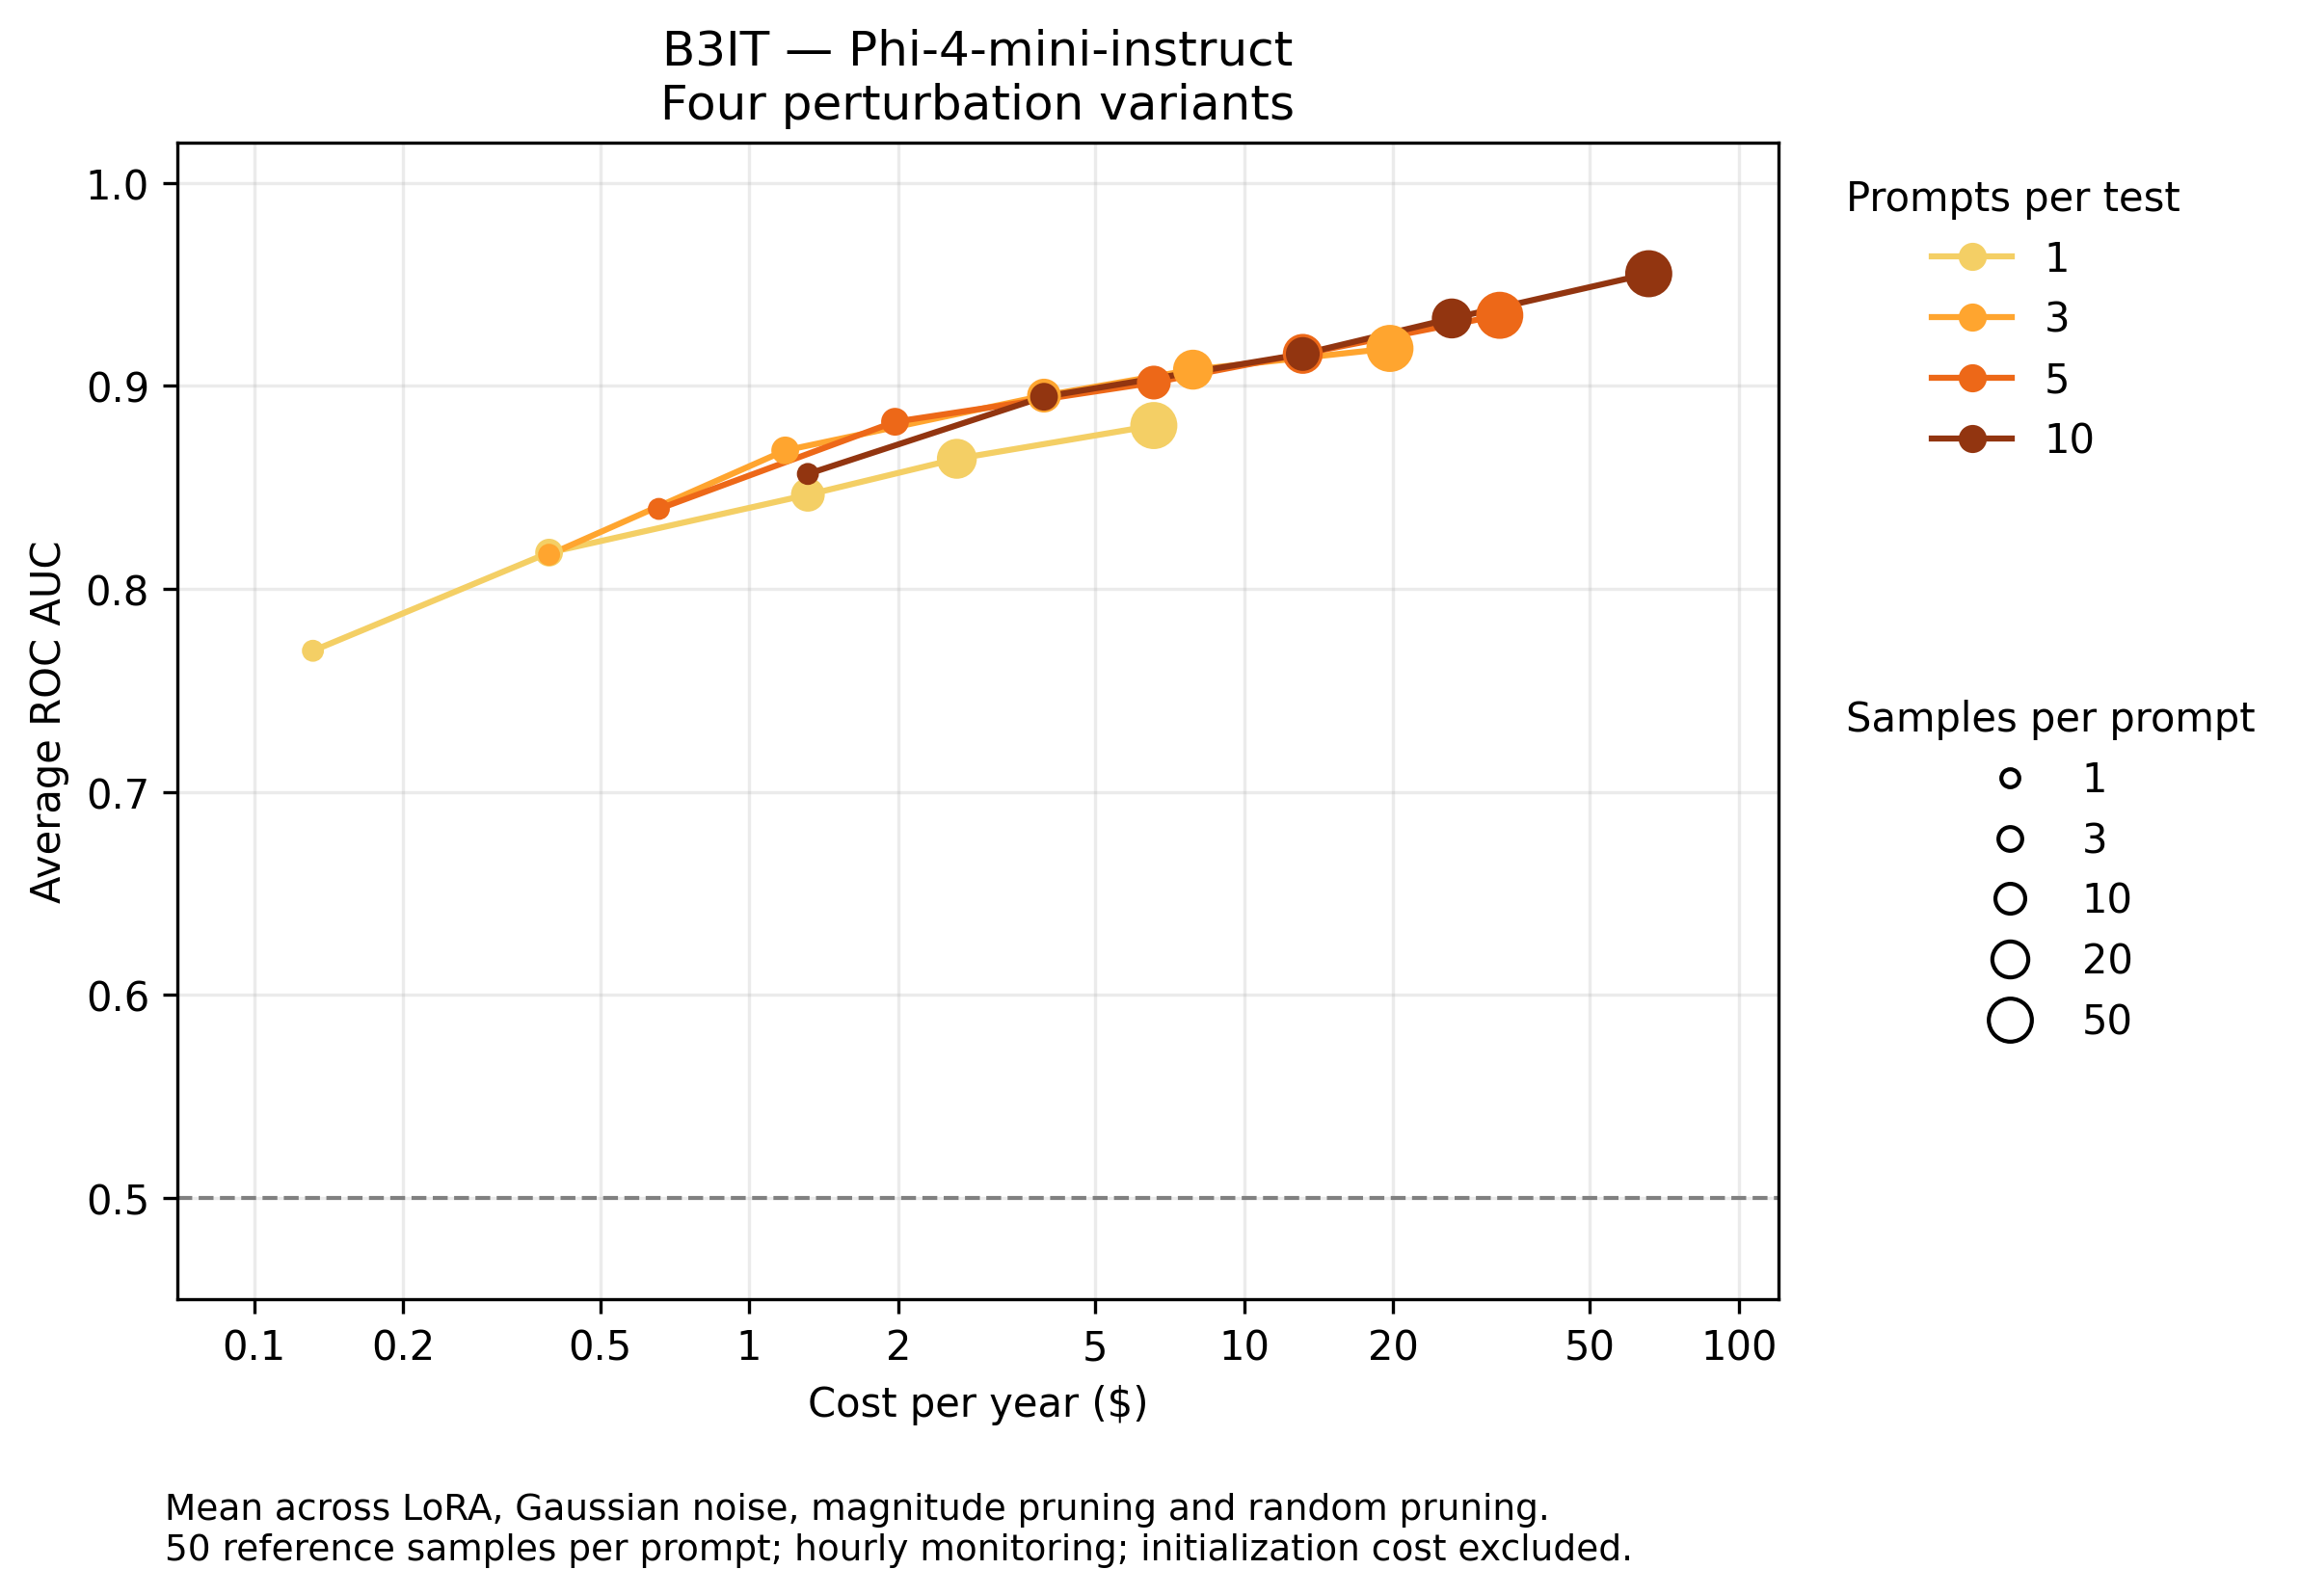

In [24]:
import os
import subprocess
from pathlib import Path
from IPython.display import Image, display

root = Path("/workspace/B3IT_Figure1_Phi4Mini")
project = root / "repo/track-llm-apis"
local = Path("/tmp/b3it-phi4mini")
script = project / "src/track_llm_apis/plot_phi_figure1.py"

code = r'''
import csv
import inspect
import json
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator

from track_llm_apis.sampling.common import DataSource, load_single_variant_results
from track_llm_apis.sampling.analyze_param_sweeps import compute_auc_from_stats
from track_llm_apis.util import compute_yearly_cost

ROOT = Path("/workspace/B3IT_Figure1_Phi4Mini")

def save_csv(path, rows):
    with path.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def main():
    output = ROOT / "results/figure1"
    output.mkdir(parents=True, exist_ok=True)
    manifest = json.loads((ROOT / "configs/phi_figure1_evaluation_manifest.json").read_text())
    expected_variants = {
        json.dumps(v["description"], sort_keys=True)
        for v in manifest["variants"] if v["id"] != "unchanged"
    }
    results = load_single_variant_results(
        [ROOT / "results/figure1_merged"], DataSource.BI
    )
    assert len(results) == 80

    print("Repository cost calculation used by Qwen and Phi:")
    print(inspect.getsource(compute_yearly_cost))

    grouped = defaultdict(list)
    records = []
    for result in results:
        p = int(result.params["n_prompts"])
        s = int(result.params["detection_samples"])
        variant = json.dumps(json.loads(result.variant), sort_keys=True)
        assert variant in expected_variants
        assert result.model_name == manifest["model"]

        auc = float(compute_auc_from_stats(
            result.h0_stats.stats, result.h1_stats.stats, sampling=False,
        ))
        # The saved averages already total all prompts in one test.
        # Use Qwen's exact cost call, without initialization/reference costs.
        cost = float(compute_yearly_cost(
            input_tokens_per_sample=result.h1_stats.input_token_avg / s,
            output_tokens_per_sample=result.h1_stats.output_token_avg / s,
            n_samples=s,
        ))
        assert np.isfinite(auc) and 0 <= auc <= 1
        assert np.isfinite(cost) and cost > 0

        row = dict(
            model=result.model_name, variant=variant, n_prompts=p,
            samples_per_prompt=s, roc_auc=auc, yearly_cost_usd=cost,
        )
        records.append(row)
        grouped[p, s].append(row)

    expected_settings = {(p, s) for p in [1, 3, 5, 10]
                         for s in [1, 3, 10, 20, 50]}
    assert set(grouped) == expected_settings
    summary = []
    for (p, s), rows in sorted(grouped.items()):
        assert len(rows) == 4
        assert {r["variant"] for r in rows} == expected_variants
        assert np.allclose([r["yearly_cost_usd"] for r in rows],
                           rows[0]["yearly_cost_usd"])
        summary.append(dict(
            n_prompts=p, samples_per_prompt=s,
            mean_roc_auc=float(np.mean([r["roc_auc"] for r in rows])),
            yearly_cost_usd=rows[0]["yearly_cost_usd"], number_of_variants=4,
        ))

    save_csv(output / "figure1_per_variant.csv",
             sorted(records, key=lambda r: (r["variant"], r["n_prompts"],
                                           r["samples_per_prompt"])))
    save_csv(output / "figure1_summary.csv", summary)

    colors = {1: "#f4cf65", 3: "#ffa52f", 5: "#ed6818", 10: "#923510"}
    sizes = {1: 20, 3: 35, 10: 55, 20: 80, 50: 115}
    fig, ax = plt.subplots(figsize=(9, 5.8))
    fig.subplots_adjust(right=0.74, bottom=0.19)
    for p, color in colors.items():
        rows = sorted([r for r in summary if r["n_prompts"] == p],
                      key=lambda r: r["samples_per_prompt"])
        x = [r["yearly_cost_usd"] for r in rows]
        y = [r["mean_roc_auc"] for r in rows]
        ax.plot(x, y, color=color, linewidth=1.5)
        ax.scatter(x, y, s=[sizes[r["samples_per_prompt"]] for r in rows],
                   color=color, zorder=3)

    ticks = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    costs = [r["yearly_cost_usd"] for r in summary]
    ax.set_xlim(min(0.07, min(costs) * 0.8), max(120, max(costs) * 1.1))
    ax.set_ylim(0.45, 1.02)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Cost per year ($)")
    ax.set_ylabel("Average ROC AUC")
    ax.set_title("B3IT — Phi-4-mini-instruct\nFour perturbation variants")
    ax.grid(True, which="major", alpha=0.25)

    legend = ax.legend(
        handles=[Line2D([0], [0], color=c, marker="o", label=str(p))
                 for p, c in colors.items()],
        title="Prompts per test", loc="upper left",
        bbox_to_anchor=(1.02, 1), frameon=False,
    )
    ax.add_artist(legend)
    ax.legend(
        handles=[Line2D([0], [0], linestyle="", marker="o",
                        markerfacecolor="none", markeredgecolor="black",
                        markersize=np.sqrt(size), label=str(s))
                 for s, size in sizes.items()],
        title="Samples per prompt", loc="upper left",
        bbox_to_anchor=(1.02, 0.55), frameon=False,
    )
    fig.text(
        0.12, 0.035,
        "Mean across LoRA, Gaussian noise, magnitude pruning and random pruning.\n"
        "50 reference samples per prompt; hourly monitoring; initialization cost excluded.",
        fontsize=9,
    )
    for extension in ["png", "pdf"]:
        fig.savefig(output / f"figure1_phi.{extension}",
                    dpi=300, bbox_inches="tight")
    plt.close(fig)

    print("\nPrompts | Samples | Mean ROC AUC | Annual cost")
    for r in summary:
        print(f'{r["n_prompts"]:7d} | {r["samples_per_prompt"]:7d} | '
              f'{r["mean_roc_auc"]:.4f} | ${r["yearly_cost_usd"]:.4f}')
    print("\nPhi figure and CSV files saved:", output)

if __name__ == "__main__":
    main()
'''

compile(code, str(script), "exec")
script.write_text(code)
env = os.environ.copy()
env.update({
    "PYTHONPATH": str(project / "src"),
    "TRACKLLM__DATA_DIR": str(root / "data"),
    "MPLBACKEND": "Agg",
})
result = subprocess.run(
    [str(local / "venv/bin/python"), "-u", "-m", "track_llm_apis.plot_phi_figure1"],
    cwd=project, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(result.stdout)
(root / "logs/phi_figure1_plot.log").write_text(result.stdout)
result.check_returncode()
display(Image(filename=str(root / "results/figure1/figure1_phi.png")))

CPU plotting environment: /tmp/b3it-phi4mini/venv/bin/python
Qwen: verified 20 settings, 80 rows, four perturbations, and summary means.
Gemma: verified 20 settings, 80 rows, four perturbations, and summary means.
Phi: verified 20 settings, 80 rows, four perturbations, and summary means.
Precisions: {'Qwen': 'float16', 'Gemma': 'bfloat16', 'Phi': 'float16'}
Saved 240 per-variant rows and 20 combined summary rows.
Outputs: /workspace/B3IT_Figure1_ThreeModels/results/figure1



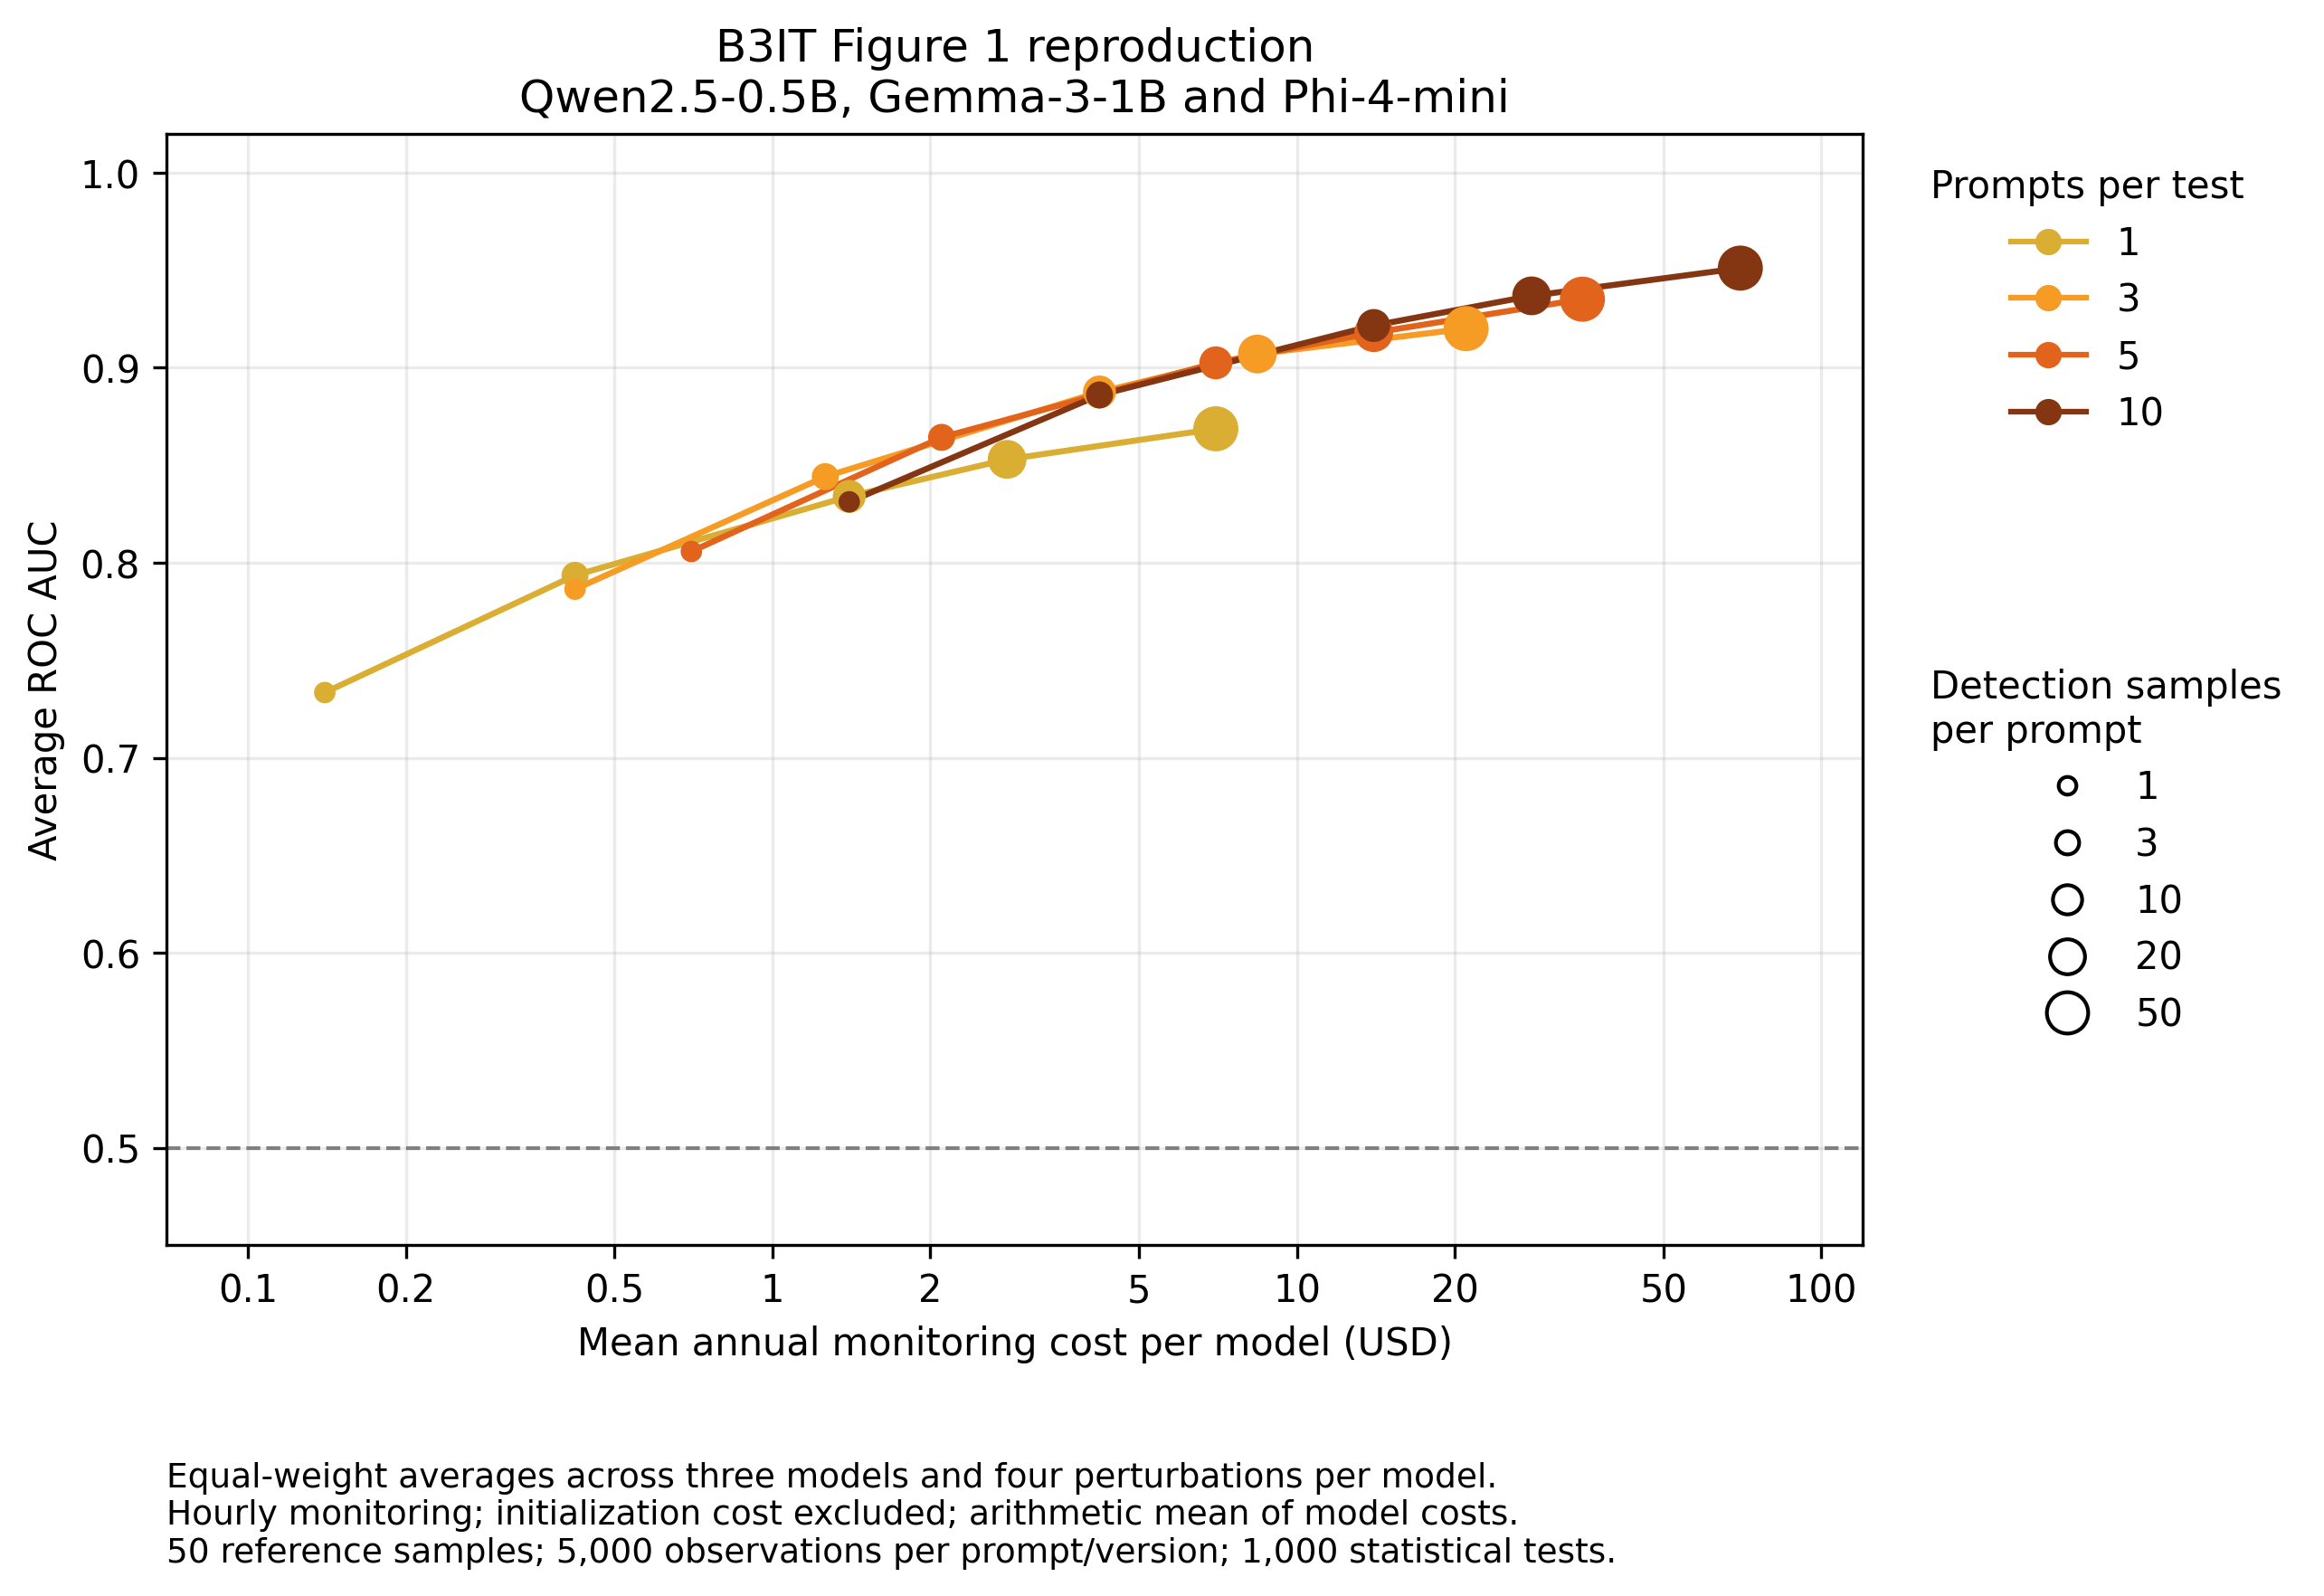

In [25]:
import os
os.environ["MPLBACKEND"] = "Agg"

import json
import shutil
import subprocess
import sys
from pathlib import Path

sources = {
    "Qwen": Path("/workspace/B3IT_Figure1_Gemma1B/results/qwen_import"),
    "Gemma": Path("/workspace/B3IT_Figure1_Gemma1B/results/figure1"),
    "Phi": Path("/workspace/B3IT_Figure1_Phi4Mini/results/figure1"),
}
filenames = ["figure1_summary.csv", "figure1_per_variant.csv"]
missing = [
    folder / name
    for folder in sources.values()
    for name in filenames
    if not (folder / name).is_file()
]
if missing:
    raise FileNotFoundError(
        "Upload the corresponding experiment CSVs to these exact paths:\n"
        + "\n".join(str(path) for path in missing)
    )

phi_config = Path(
    "/workspace/B3IT_Figure1_Phi4Mini/configs/"
    "phi_figure1_evaluation_manifest.json"
)
if not phi_config.is_file():
    raise FileNotFoundError(
        f"Upload Phi's saved evaluation manifest to:\n{phi_config}"
    )

# Find an existing environment with the plotting dependencies.
candidates = [
    sys.executable,
    "/tmp/b3it-phi4mini/venv/bin/python",
    "/workspace/B3IT_Figure1_Gemma1B/repo/track-llm-apis/.venv/bin/python",
    shutil.which("python3"),
]
env = os.environ.copy()
env.update({"MPLBACKEND": "Agg", "CUDA_VISIBLE_DEVICES": ""})
python = None
for candidate in dict.fromkeys(p for p in candidates if p):
    if Path(candidate).is_file():
        check = subprocess.run(
            [candidate, "-c", "import numpy, matplotlib"],
            env=env, capture_output=True, text=True,
        )
        if check.returncode == 0:
            python = candidate
            break
if python is None:
    raise RuntimeError(
        "No available Python environment contains numpy and matplotlib. "
        "Paste this message so we can fix the environment."
    )
print("CPU plotting environment:", python)

base = Path("/workspace/B3IT_Figure1_ThreeModels")
script = base / "plot_combined_figure1.py"

code = r'''
import os
os.environ["MPLBACKEND"] = "Agg"

import csv
import hashlib
import json
import math
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator

BASE = Path("/workspace/B3IT_Figure1_ThreeModels")
OUTPUT = BASE / "results/figure1"
SOURCES = {
    "Qwen": Path("/workspace/B3IT_Figure1_Gemma1B/results/qwen_import"),
    "Gemma": Path("/workspace/B3IT_Figure1_Gemma1B/results/figure1"),
    "Phi": Path("/workspace/B3IT_Figure1_Phi4Mini/results/figure1"),
}
MODEL_IDS = {
    "Qwen": "Qwen/Qwen2.5-0.5B-Instruct",
    "Gemma": "google/gemma-3-1b-it",
    "Phi": "microsoft/Phi-4-mini-instruct",
}
PHI_CONFIG = Path(
    "/workspace/B3IT_Figure1_Phi4Mini/configs/"
    "phi_figure1_evaluation_manifest.json"
)
PROMPT_COUNTS = [1, 3, 5, 10]
SAMPLE_COUNTS = [1, 3, 10, 20, 50]
SETTINGS = {(p, s) for p in PROMPT_COUNTS for s in SAMPLE_COUNTS}

EXPECTED_DESCRIPTIONS = {
    "lora": {"type": "finetune", "lr": 1e-6, "n_samples": 128, "lora": True},
    "noise": {"type": "random_noise", "scale": 2**-12},
    "magnitude": {
        "type": "weight_pruning", "method": "magnitude", "scale": 2**-8,
    },
    "random": {
        "type": "weight_pruning", "method": "random", "scale": 2**-8,
    },
}

def require(condition, message):
    if not condition:
        raise ValueError(message)

def read_csv(path, required_columns):
    if not path.is_file():
        raise FileNotFoundError(f"Upload this CSV to exactly:\n{path}")
    with path.open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        require(required_columns <= set(reader.fieldnames or []),
                f"Missing columns in {path}: {required_columns - set(reader.fieldnames or [])}")
        return list(reader)

def key(row):
    return int(row["n_prompts"]), int(row["samples_per_prompt"])

def number(value, label, auc=False):
    result = float(value)
    require(math.isfinite(result), f"Non-finite {label}")
    require(0 <= result <= 1 if auc else result > 0, f"Invalid {label}: {result}")
    return result

def close(a, b):
    return math.isclose(a, b, rel_tol=1e-8, abs_tol=1e-10)

def save_csv(path, rows):
    temporary = path.with_suffix(".csv.tmp")
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def main():
    if not PHI_CONFIG.is_file():
        raise FileNotFoundError(f"Upload Phi's evaluation manifest to:\n{PHI_CONFIG}")
    phi = json.loads(PHI_CONFIG.read_text())
    require(phi["model"] == MODEL_IDS["Phi"], "Unexpected Phi model in manifest")
    phi_precision = phi["inference_dtype"]
    require(phi_precision in ("float16", "bfloat16", "float32"),
            f"Unrecognized Phi precision: {phi_precision}")

    sampling = phi["sampling"]
    analysis = phi["analysis"]
    require(sampling["observations_per_prompt_per_version"] == 5000,
            "Phi observation count differs")
    require(analysis["reference_samples_per_prompt"] == 50,
            "Phi reference count differs")
    require(analysis["repeated_tests"] == 1000, "Phi test count differs")
    require(analysis["prompt_counts"] == PROMPT_COUNTS, "Phi prompt settings differ")
    require(analysis["detection_sample_counts"] == SAMPLE_COUNTS,
            "Phi sample settings differ")

    precision = {"Qwen": "float16", "Gemma": "bfloat16", "Phi": phi_precision}
    validated = {}
    combined_variants = []
    source_hashes = {}

    for label, folder in SOURCES.items():
        summary_path = folder / "figure1_summary.csv"
        variant_path = folder / "figure1_per_variant.csv"
        summaries = read_csv(summary_path, {
            "n_prompts", "samples_per_prompt", "mean_roc_auc",
            "yearly_cost_usd", "number_of_variants",
        })
        variants = read_csv(variant_path, {
            "model", "variant", "n_prompts", "samples_per_prompt",
            "roc_auc", "yearly_cost_usd",
        })
        require(len(summaries) == 20, f"{label}: expected 20 summary rows")
        require(len(variants) == 80, f"{label}: expected 80 per-variant rows")

        summary_by_setting = {}
        for row in summaries:
            setting = key(row)
            require(setting in SETTINGS and setting not in summary_by_setting,
                    f"{label}: duplicate or unexpected summary setting {setting}")
            require(int(row["number_of_variants"]) == 4,
                    f"{label}: summary must average four variants")
            summary_by_setting[setting] = (
                number(row["mean_roc_auc"], f"{label} summary AUC", auc=True),
                number(row["yearly_cost_usd"], f"{label} summary cost"),
            )
        require(set(summary_by_setting) == SETTINGS, f"{label}: missing settings")

        grouped = {setting: {} for setting in SETTINGS}
        for row in variants:
            setting = key(row)
            require(setting in SETTINGS, f"{label}: unexpected setting {setting}")
            require(row["model"] == MODEL_IDS[label],
                    f"{label}: unexpected model ID {row['model']!r}")
            description = json.loads(row["variant"])
            matches = [name for name, expected in EXPECTED_DESCRIPTIONS.items()
                       if description == expected]
            require(len(matches) == 1,
                    f"{label}: unexpected perturbation description {description}")
            perturbation = matches[0]
            require(perturbation not in grouped[setting],
                    f"{label}: duplicate {perturbation} at {setting}")

            auc = number(row["roc_auc"], f"{label} variant AUC", auc=True)
            cost = number(row["yearly_cost_usd"], f"{label} variant cost")
            grouped[setting][perturbation] = (auc, cost)
            combined_variants.append({
                "model": MODEL_IDS[label],
                "perturbation": perturbation,
                "variant": json.dumps(description, sort_keys=True),
                "n_prompts": setting[0],
                "samples_per_prompt": setting[1],
                "roc_auc": auc,
                "yearly_cost_usd": cost,
                "evaluation_precision": precision[label],
            })

        for setting, entries in grouped.items():
            require(set(entries) == set(EXPECTED_DESCRIPTIONS),
                    f"{label}: incomplete perturbations at {setting}")
            mean_auc = float(np.mean([a for a, _ in entries.values()]))
            summary_auc, summary_cost = summary_by_setting[setting]
            require(close(mean_auc, summary_auc),
                    f"{label}: summary AUC disagrees at {setting}")
            require(all(close(c, summary_cost) for _, c in entries.values()),
                    f"{label}: variant and summary costs disagree at {setting}")

        validated[label] = summary_by_setting
        source_hashes[label] = {
            "summary": {"path": str(summary_path), "sha256": sha256(summary_path)},
            "per_variant": {"path": str(variant_path), "sha256": sha256(variant_path)},
        }
        print(f"{label}: verified 20 settings, 80 rows, four perturbations, and summary means.")

    summary = []
    for p, s in sorted(SETTINGS):
        row = {"n_prompts": p, "samples_per_prompt": s}
        for label in SOURCES:
            auc, cost = validated[label][p, s]
            row[f"{label.lower()}_mean_roc_auc"] = auc
            row[f"{label.lower()}_yearly_cost_usd"] = cost
        row["combined_mean_roc_auc"] = float(np.mean(
            [validated[label][p, s][0] for label in SOURCES]
        ))
        row["mean_annual_cost_per_model_usd"] = float(np.mean(
            [validated[label][p, s][1] for label in SOURCES]
        ))
        row["number_of_models"] = 3
        row["perturbations_per_model"] = 4
        summary.append(row)

    OUTPUT.mkdir(parents=True, exist_ok=True)
    save_csv(OUTPUT / "figure1_three_models_per_variant.csv", sorted(
        combined_variants,
        key=lambda r: (r["model"], r["perturbation"],
                       r["n_prompts"], r["samples_per_prompt"]),
    ))
    save_csv(OUTPUT / "figure1_three_models_summary.csv", summary)

    colors = {1: "#d9ae32", 3: "#f69b24", 5: "#e2631b", 10: "#843613"}
    sizes = {1: 22, 3: 38, 10: 60, 20: 86, 50: 120}
    fig, ax = plt.subplots(figsize=(10, 6.3))
    fig.subplots_adjust(right=0.75, bottom=0.23)

    for p, color in colors.items():
        rows = sorted([r for r in summary if r["n_prompts"] == p],
                      key=lambda r: r["samples_per_prompt"])
        x = [r["mean_annual_cost_per_model_usd"] for r in rows]
        y = [r["combined_mean_roc_auc"] for r in rows]
        ax.plot(x, y, color=color, linewidth=1.6)
        ax.scatter(x, y, color=color,
                   s=[sizes[r["samples_per_prompt"]] for r in rows], zorder=3)

    ticks = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]
    costs = [r["mean_annual_cost_per_model_usd"] for r in summary]
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(min(0.07, min(costs) * 0.8), max(120, max(costs) * 1.1))
    aucs = [r["combined_mean_roc_auc"] for r in summary]
    ax.set_ylim(min(0.45, min(aucs) - 0.03), 1.02)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Mean annual monitoring cost per model (USD)")
    ax.set_ylabel("Average ROC AUC")
    ax.set_title(
        "B3IT Figure 1 reproduction\n"
        "Qwen2.5-0.5B, Gemma-3-1B and Phi-4-mini"
    )
    ax.grid(True, which="major", alpha=0.25)

    legend = ax.legend(
        handles=[Line2D([0], [0], color=c, marker="o", label=str(p))
                 for p, c in colors.items()],
        title="Prompts per test", loc="upper left",
        bbox_to_anchor=(1.02, 1), frameon=False,
    )
    ax.add_artist(legend)
    ax.legend(
        handles=[Line2D(
            [0], [0], linestyle="", marker="o",
            markerfacecolor="none", markeredgecolor="black",
            markersize=np.sqrt(size), label=str(s),
        ) for s, size in sizes.items()],
        title="Detection samples\nper prompt", loc="upper left",
        bbox_to_anchor=(1.02, 0.55), frameon=False,
    )
    fig.text(
        0.125, 0.045,
        "Equal-weight averages across three models and four perturbations per model.\n"
        "Hourly monitoring; initialization cost excluded; arithmetic mean of model costs.\n"
        "50 reference samples; 5,000 observations per prompt/version; 1,000 statistical tests.",
        fontsize=9,
    )
    for extension in ("png", "pdf"):
        fig.savefig(OUTPUT / f"figure1_three_models.{extension}",
                    dpi=300, bbox_inches="tight")
    plt.close(fig)

    metadata = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "models": MODEL_IDS,
        "evaluation_precision": precision,
        "precision_sources": {
            "Qwen": "User-confirmed FP16",
            "Gemma": "User-confirmed BF16",
            "Phi": {"path": str(PHI_CONFIG), "sha256": sha256(PHI_CONFIG),
                    "field": "inference_dtype"},
        },
        "perturbations": EXPECTED_DESCRIPTIONS,
        "prompt_counts": PROMPT_COUNTS,
        "detection_samples": SAMPLE_COUNTS,
        "reference_samples": 50,
        "observations_per_prompt_version": 5000,
        "statistical_tests": 1000,
        "auc_aggregation": "Arithmetic mean of the three model means; each model "
                           "mean averages its four perturbation AUCs.",
        "cost_aggregation": "Arithmetic mean of the three saved annual model costs.",
        "monitoring_frequency": "hourly",
        "initialization_cost_included": False,
        "settings_provenance": "Shared experiment settings supplied by the user; "
                               "Phi counts also checked against its saved manifest.",
        "cost_provenance": "Uses saved CSV costs without recalculating token pricing.",
        "sources": source_hashes,
        "combined_per_variant_rows": len(combined_variants),
        "combined_summary_rows": len(summary),
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "plotting_script": str(Path(__file__).resolve()),
        "plotting_script_sha256": sha256(Path(__file__)),
    }
    (OUTPUT / "figure1_three_models_metadata.json").write_text(
        json.dumps(metadata, indent=2), encoding="utf-8",
    )

    print("Precisions:", precision)
    print("Saved 240 per-variant rows and 20 combined summary rows.")
    print("Outputs:", OUTPUT)

if __name__ == "__main__":
    main()
'''

compile(code, str(script), "exec")
base.mkdir(parents=True, exist_ok=True)
script.write_text(code, encoding="utf-8")

result = subprocess.run(
    [python, "-u", str(script)],
    env=env, capture_output=True, text=True,
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError("Validation or plotting failed. Paste the error above.")

from IPython.display import Image, display
display(Image(filename=str(
    base / "results/figure1/figure1_three_models.png"
)))